# UNSEEN heat plots modified for AGU25 Presentation

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt  # noqa
import numpy as np
from pathlib import Path
import xarray as xr
import sys

sys.path.append("/g/data/xv83/unseen-projects/code")
from unseen import general_utils, eva
from spatial_plots_multimodel import *

In [2]:
fontsize = 16
plt.rcParams.update({"font.size": fontsize})

In [4]:
metric = "txx"
obs_config_file = "AGCD-CSIRO_r05_tasmax_config.mk"
obs = "AGCD"
bc = "additive"
project = "txx"

In [5]:
# Required parameters
kwargs = locals()
assert "metric" in kwargs, "Must provide a metric name (e.g., txx)"
assert (
    "obs_config_file" in kwargs
), "Must provide a obs_config_file name (e.g., AGCD-tasmax_config.mk)"
assert "obs" in kwargs, "Must provide a observation data set name (e.g., AGCD)"
if "project" not in kwargs:
    kwargs["project"] = metric

In [6]:
if metric == "txx":
    models = np.array(
        [
            "CAFE",
            "BCC-CSM2-MR",
            "CanESM5",
            "CMCC-CM2-SR5",
            "EC-Earth3",
            "IPSL-CM6A-LR",
            "MIROC6",
            "MPI-ESM1-2-HR",
            "MRI-ESM2-0",
            "NorCPM1",
        ]
    )
elif metric == "rx1day":
    models = np.array(
        [
            "BCC-CSM2-MR",
            "CanESM5",
            "CMCC-CM2-SR5",
            "EC-Earth3",
            "HadGEM3-GC31-MM",
            "IPSL-CM6A-LR",
            "MIROC6",
            "MPI-ESM1-2-HR",
            "MRI-ESM2-0",
            "NorCPM1",
        ]
    )

In [7]:
# Get variables from makefile (nested dictionary)
var_dict = get_makefile_vars(
    models, metric, obs, obs_config_file=obs_config_file, project=project
)

In [8]:
# Filestem for figures and datatree
filestem_no_bc = f"{metric}_{var_dict[obs]['timescale']}_{var_dict[obs]['region']}"
filestem = filestem_no_bc + f"_bias-corrected-{var_dict[obs]['obs_dataset']}-{bc}"

dt_file_no_bc = f"{var_dict[obs]['project_dir']}/data/datatree_{filestem_no_bc}.nc"
dt_file = f"{var_dict[obs]['project_dir']}/data/datatree_{filestem}.nc"

In [9]:
# Extract some variables from the dictionaries
plot_dict = eval(var_dict[obs]["plot_dict"])
map_plot_kwargs = plot_dict.pop("map_plot_kwargs")
var = var_dict[obs]["var"]
time_agg = var_dict[obs]["time_agg"]
covariate_base = int(var_dict[obs]["covariate_base"])
covariates = eval(var_dict[obs]["gev_trend_period"])
plot_dict["fig_dir"] = Path(var_dict[obs]["fig_dir"]) / "AGU2025"
plot_dict["filestem"] = filestem
plot_dict["filestem_no_bc"] = filestem.split("_bias")[0]
plot_dict["models"] = models

plot_dict_avg = plot_dict.copy()
stability_kwargs = {}
stability_anom_kwargs = {}

if metric == "txx":
    std_dev_ticks = np.arange(0, 4.5, 0.5)  # Median absolute deviation
    if bc is None:
        plot_dict_avg["ticks"] = np.arange(22, 52 + 4, 4)
        plot_dict["ticks"] = np.arange(24, 66 + 4, 4)
    else:
        plot_dict_avg["ticks"] = np.arange(22, 52 + 4, 4)
        plot_dict["ticks"] = np.arange(32, 56 + 2, 2)

    stability_anom_kwargs = dict(
        ticks=np.arange(-3.3, 3.5, 0.2),
        ticklabels=np.around(np.arange(-3.2, 3.4, 0.2), 1),
    )

elif metric == "rx1day":
    std_dev_ticks = np.arange(0, 50 + 10, 10)  # Median absolute deviation
    if bc is None:
        plot_dict_avg["ticks"] = np.arange(0, 200 + 20, 20)
        plot_dict["ticks"] = np.arange(0, 400 + 50, 50)
    else:
        plot_dict_avg["ticks"] = np.arange(0, 120 + 20, 20)
        plot_dict_avg["ticks_anom"] = np.arange(-11, 11 + 2, 2)
        plot_dict["ticks"] = np.arange(0, 450 + 50, 50)
        plot_dict["ticks_anom"] = np.arange(-170, 170 + 40, 40)

In [10]:
# Create/open datatree of all model and observation datasets
if Path(dt_file).exists():
    # dt_no_bc = xr.open_datatree(dt_file_no_bc)
    dt = xr.open_datatree(dt_file)
else:
    print("Need to create datatree files first.")
dt

<xarray.DataTree>
Group: /
├── Group: /obs
│   └── Group: /obs/AGCD
│           Dimensions:     (time: 63, lat: 70, lon: 89, dparams: 5)
│           Coordinates:
│             * lat         (lat) float64 560B -44.5 -44.0 -43.5 -43.0 ... -11.0 -10.5 -10.0
│             * lon         (lon) float64 712B 112.0 112.5 113.0 113.5 ... 155.0 155.5 156.0
│             * time        (time) datetime64[ns] 504B 1961-06-30 1962-06-30 ... 2023-06-30
│               event_time  (time, lat, lon) datetime64[ns] 3MB ...
│             * dparams     (dparams) <U10 200B 'c' 'location_0' ... 'scale_0' 'scale_1'
│           Data variables:
│               tasmax      (time, lat, lon) float32 2MB ...
│               dparams_ns  (lat, lon, dparams) float64 249kB ...
│           Attributes: (12/34)
│               url:                           http://www.bom.gov.au/climate/
│               geospatial_lon_min:            111.975
│               bom-cmp-awap_version:          bom-cmp-awap-1.00-100.1.x86_64
│               id:                            Australian Gridded Climate Data (AGCD)
│               keywords:                      Earth Science, Atmosphere, Atmospheric Tem...
│               time_coverage_start:           1910-01-01T09:00:00
│               ...                            ...
│               geospatial_lat_min:            -44.525
│               analysis_components:           mean: the gridded temperature value
│               netcdf_version:                4.3.0 of Jul 16 2013 05:46:56 $
│               date_created:                  2018-08-16T23:46:11.477864
│               licence:                       Copyright for any data supplied by the Bur...
│               cdm_data_type:                 Grid
└── Group: /model
    ├── Group: /model/CAFE
    │       Dimensions:          (sample: 34944, lat: 19, lon: 19, dparams: 5, month: 2,
    │                             lead_time: 9, quantile: 2, bounds: 2)
    │       Coordinates:
    │         * lon              (lon) float64 152B 111.2 113.8 116.2 ... 151.2 153.8 156.2
    │         * lat              (lat) float64 152B -45.51 -43.48 -41.46 ... -11.12 -9.101
    │         * dparams          (dparams) <U10 200B 'c' 'location_0' ... 'scale_1'
    │         * lead_time        (lead_time) int64 72B 0 1 2 3 4 5 6 7 8
    │         * month            (month) int64 16B 5 11
    │         * quantile         (quantile) float64 16B 0.005 0.995
    │         * bounds           (bounds) <U5 40B 'lower' 'upper'
    │           event_time       (sample, lat, lon) object 101MB ...
    │           ensemble         (sample) int64 280kB ...
    │           init_date        (sample) object 280kB ...
    │           time             (sample) object 280kB ...
    │       Dimensions without coordinates: sample
    │       Data variables:
    │           tasmax           (sample, lat, lon) float32 50MB ...
    │           ks_pval          (lat, lon) float32 1kB ...
    │           pval_mask        (lat, lon) bool 361B ...
    │           dparams_ns       (lat, lon, dparams) float64 14kB ...
    │           covariate        (sample) int64 280kB ...
    │           r                (month, lead_time, lat, lon) float64 52kB ...
    │           ci               (month, quantile, lat, lon) float64 12kB ...
    │           min_lead         (month, lat, lon) int64 6kB ...
    │           min_lead_median  (month) float64 16B ...
    │           ci_median        (lat, lon, bounds) float64 6kB ...
    │           ci_aep           (lat, lon, bounds) float64 6kB ...
    │       Attributes:
    │           filename:   atmos_hybrid_daily.zarr
    │           grid_tile:  N/A
    │           grid_type:  regular
    │           title:      AccessOcean-AM2
    │           history:    Thu May 15 04:26:31 2025: /g/data/xv83/as3189/conda/envs/unse...
    ├── Group: /model/BCC-CSM2-MR
    │       Dimensions:          (sample: 3888, lat: 33, lon: 40, dparams: 5, month: 1,
    │                             lead_time: 9, quanti

In [11]:
# Create nested dict of class instance containing variables and datasets
info = {}
info[obs] = InfoSet(
    name=obs,
    file=var_dict[obs]["metric_obs"],
    obs_name=obs,
    ds=dt[f"obs/{obs}"].ds,
    obs_ds=dt[f"obs/{obs}"].ds,
    bias_correction=bc,
    pval_mask=None,
    **plot_dict,
)

for m in models:
    info[m] = InfoSet(
        name=m,
        obs_name=obs,
        file=var_dict[m]["metric_fcst"],
        ds=dt[f"model/{m}"].ds,
        obs_ds=subset_obs_dataset(dt[f"obs/{obs}"].ds, dt[f"model/{m}"].ds),
        pval_mask=dt[f"model/{m}"].ds.pval_mask,
        bias_correction=bc,
        **plot_dict,
    )
    info[m].regridder = shared_grid_regridder(info[m].ds, method="conservative")

for m in info.keys():
    info[m].gev_mask = get_gev_mask(info, m, var_dict, test=var_dict[m]["gev_test"])

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

In [15]:
# Number of samples
n = []
for m in models:
    n.append(info[m].ds["tasmax"].dropna("sample").sample.size)

n = np.array(n)
print("Number of samples per model:", n)
total_n = n.sum()
print("Total number of samples:", total_n)

total_n = n[1:].sum()
print("Total number of samples (minus cafe):", total_n)
n_cafe = n[0]
print("Number of samples in cafe:", n_cafe)

Number of samples per model: [34944  3888  7980  7200  6960  4560  4130  5310  2400  9440]
Total number of samples: 86812
Total number of samples (minus cafe): 51868
Number of samples in cafe: 34944


In [23]:
2018 - 1961

57

## Plots


### Single grid point

In [25]:
name = "Melbourne"
model = "MPI-ESM1-2-HR"
coords = [-37.8, 145]
da = info[model].ds[var].sel(lat=coords[0], lon=coords[1], method="nearest")
da_obs = info[obs].obs_ds[var].sel(lat=coords[0], lon=coords[1], method="nearest")

/scratch/xv83/as3189/tmp/ipykernel_523382/270347247.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


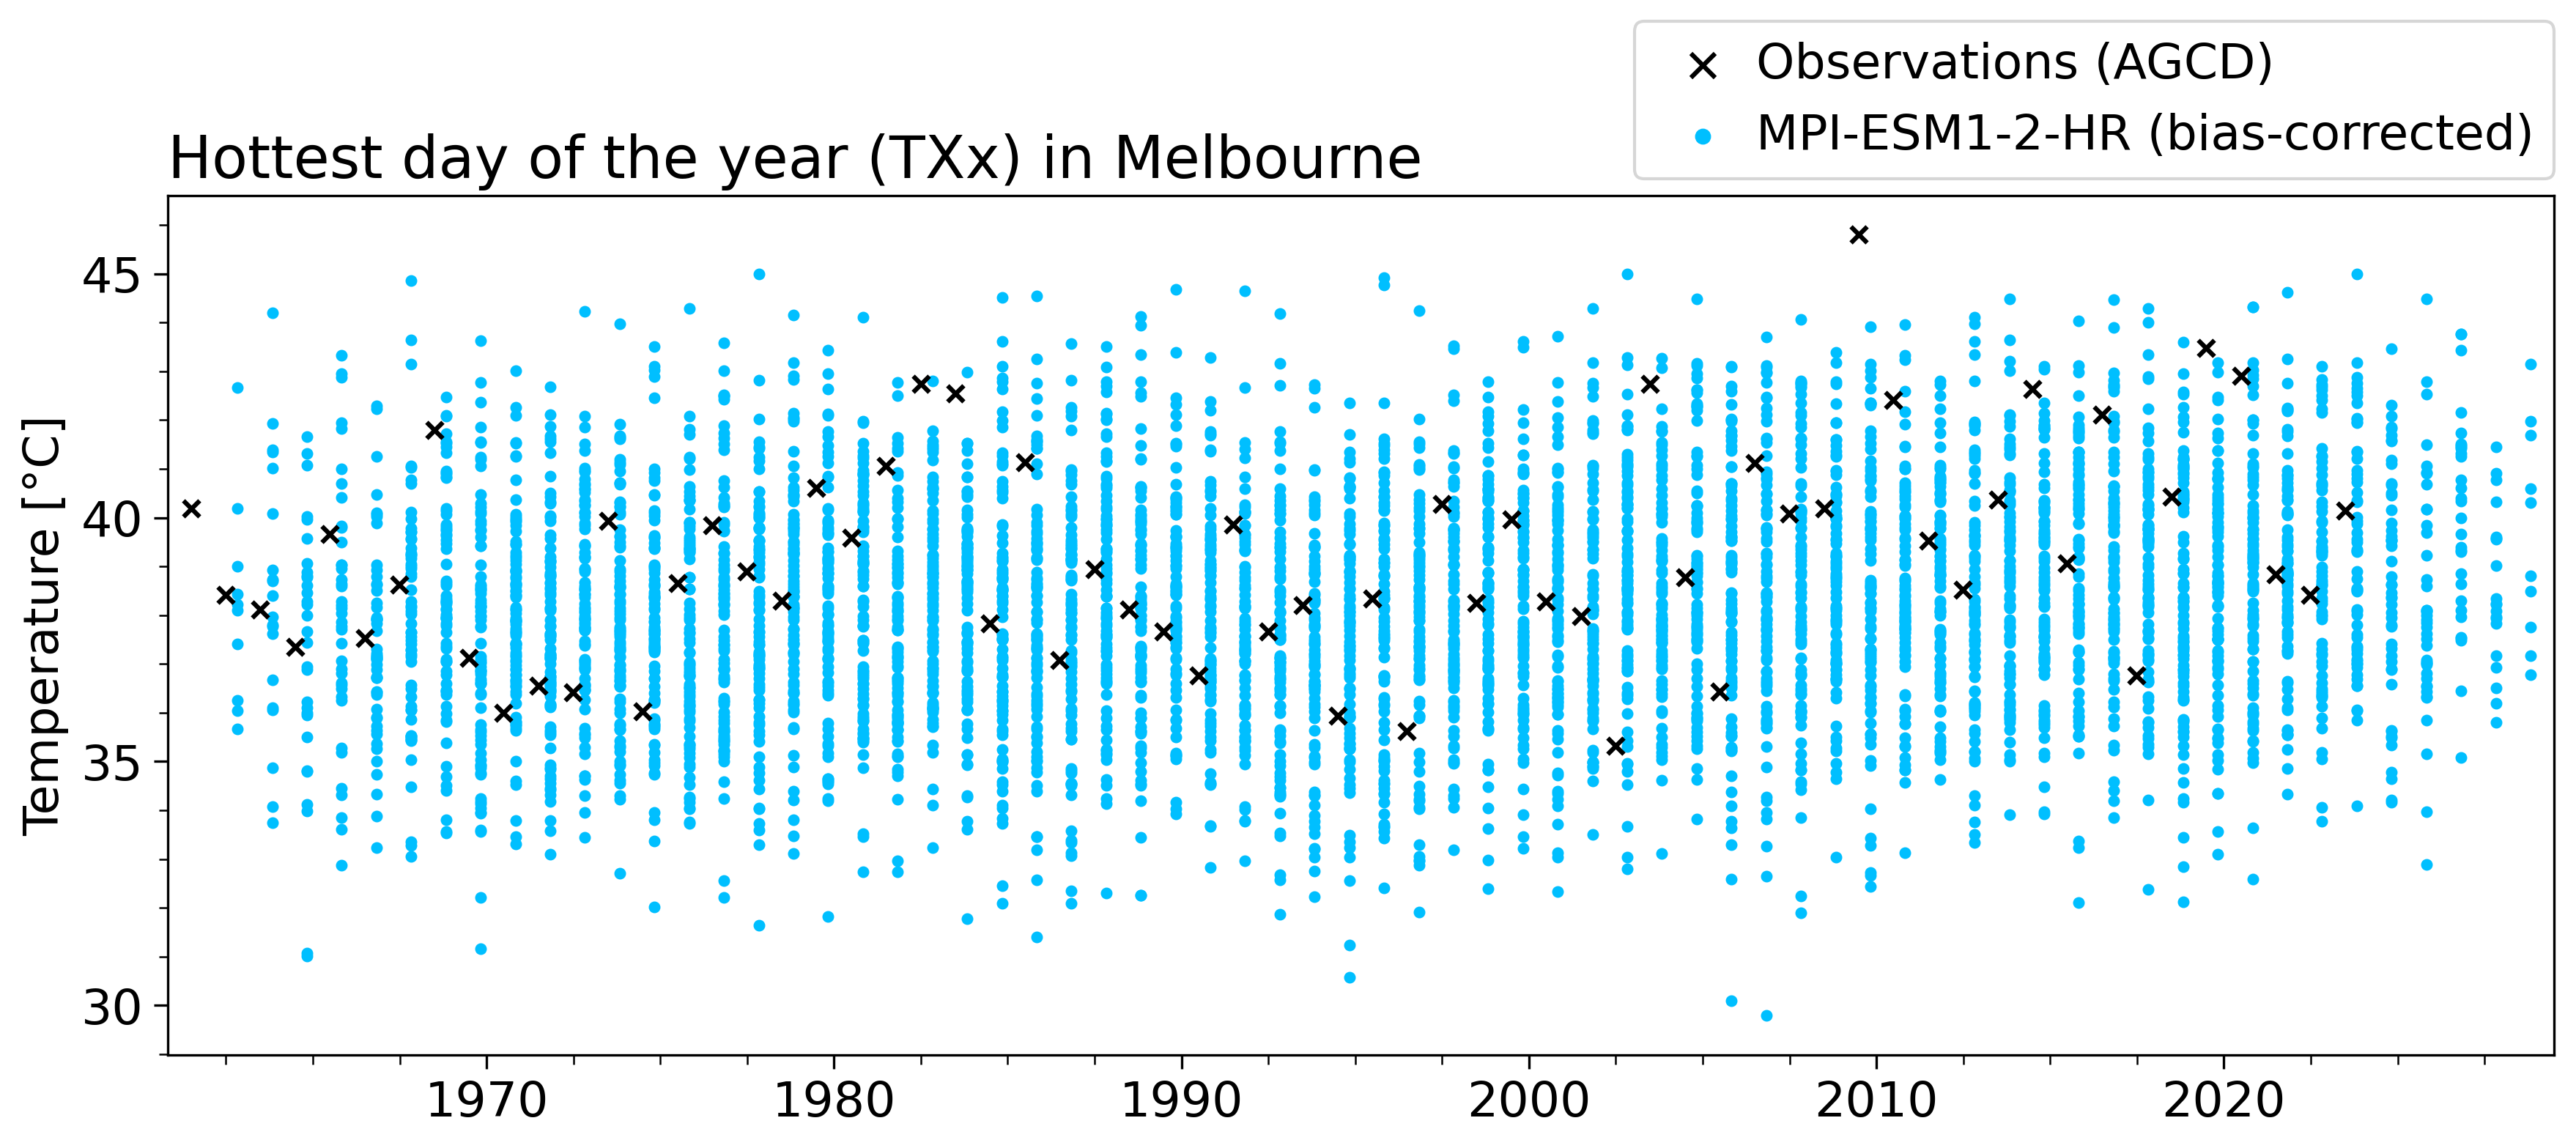

In [26]:
# AGCD & model time series (scatter)
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
ax = general_utils.plot_timeseries_scatter(
    da,
    da_obs,
    ax=ax,
    title=f"Hottest day of the year (TXx) in {name}",
    label=f"{model} (bias-corrected)",
    obs_label="Observations (AGCD)",
    units=plot_dict["units_label"],
    time_dim="time",
    add_legend=False,
)
fig.legend(
    markerscale=1.5,
    handletextpad=0.1,
    bbox_to_anchor=(0.98, 0.91),
    loc="lower right",
    borderaxespad=0.0,
)
ax.set_yticks(np.arange(30, 50, 5))
outfile = f"{plot_dict['fig_dir']}/timeseries_{name.lower()}_{model}_{plot_dict['filestem']}.png"
plt.tight_layout()
plt.savefig(outfile, dpi=200, bbox_inches="tight")

In [15]:
# Stationary parameters
dparams_s = eva.fit_gev(da, stationary=True, core_dim="sample", use_basinhopping=True)
covariate = da.time.dt.year
dparams = (
    info[model].ds["dparams_ns"].sel(lat=coords[0], lon=coords[1], method="nearest")
)

/g/data/xv83/as3189/unseen/unseen/eva.py:491: RuntimeWarning: invalid value encountered in log
  np.log(scale) + (1 + 1 / shape) * np.log(Z) + np.power(Z, -1 / shape),
/g/data/xv83/as3189/unseen/unseen/eva.py:491: RuntimeWarning: invalid value encountered in power
  np.log(scale) + (1 + 1 / shape) * np.log(Z) + np.power(Z, -1 / shape),


/g/data/xv83/as3189/unseen/unseen/eva.py:1423: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


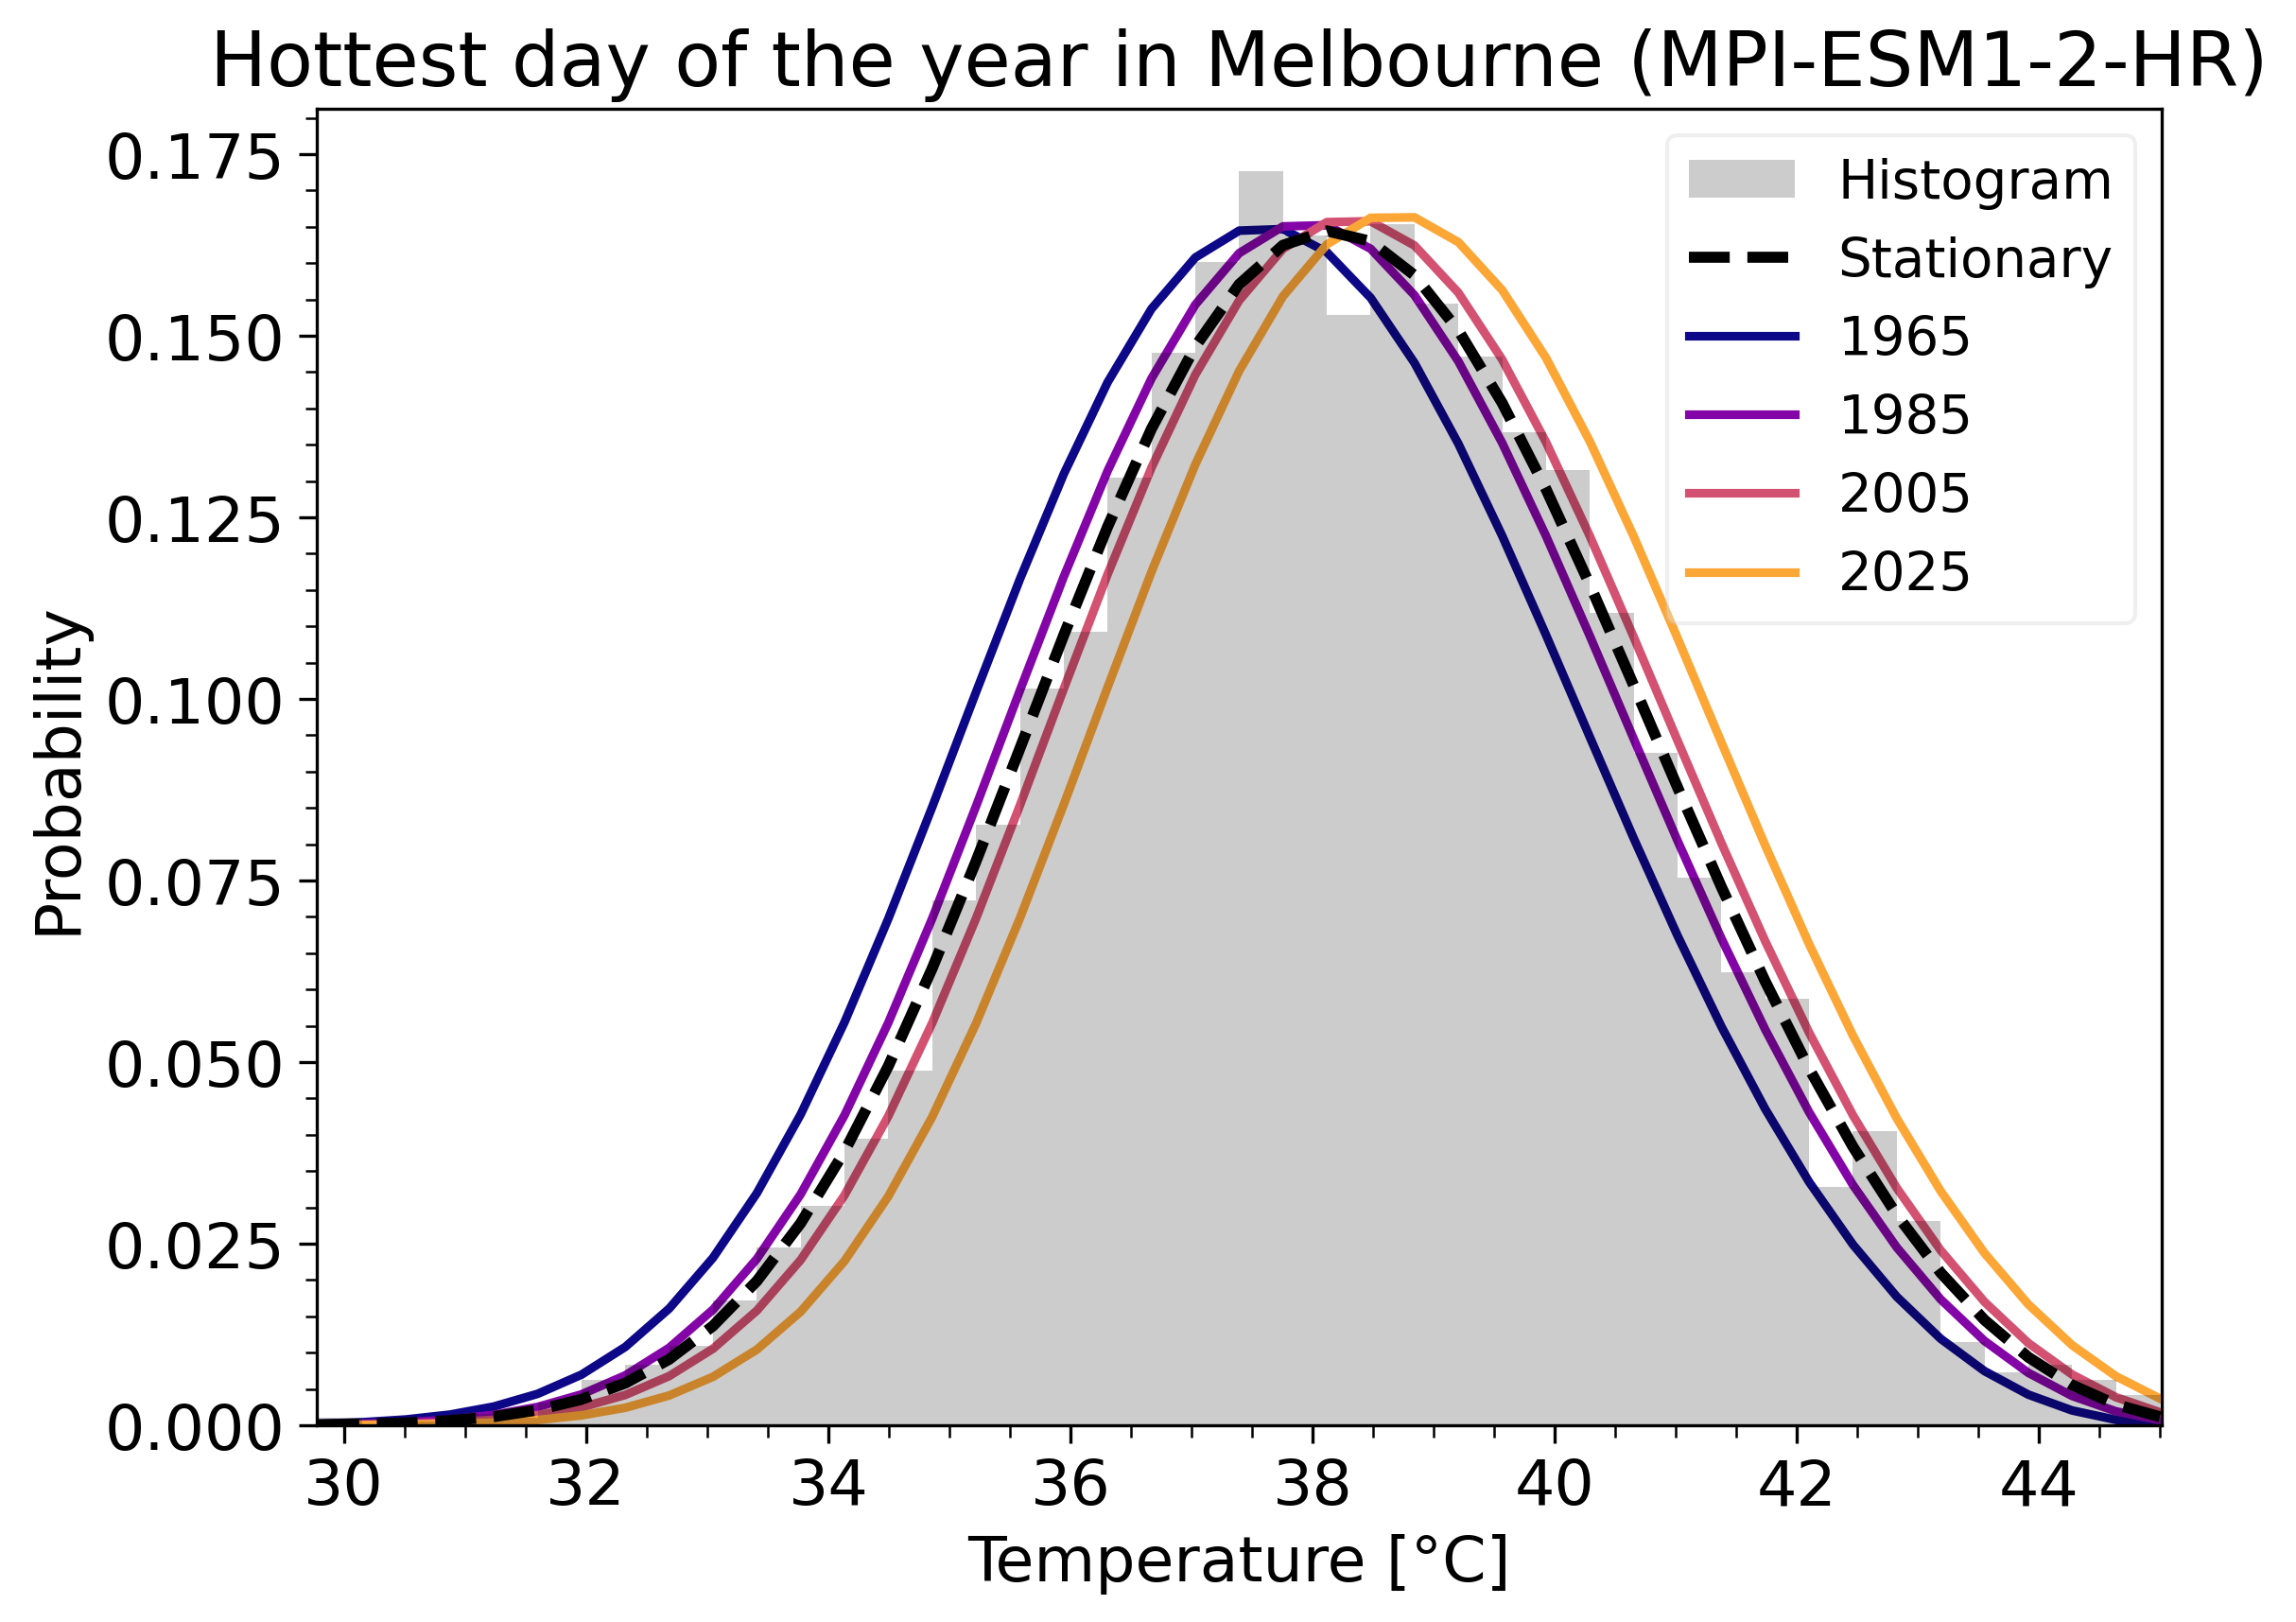

In [38]:
# Model PDFs
x = xr.DataArray(np.arange(1965, 2030, 20), dims="time")
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax = eva.plot_nonstationary_pdfs(
    da,
    dparams_s,
    dparams,
    x,
    ax,
    title=f"Hottest day of the year in {name} ({model})",
    units=plot_dict["units_label"],
    cmap="plasma",
    outfile=f"{plot_dict['fig_dir']}/PDFs_{name.lower()}_{model}_{plot_dict['filestem']}.png",
)

### Maximum anomalies

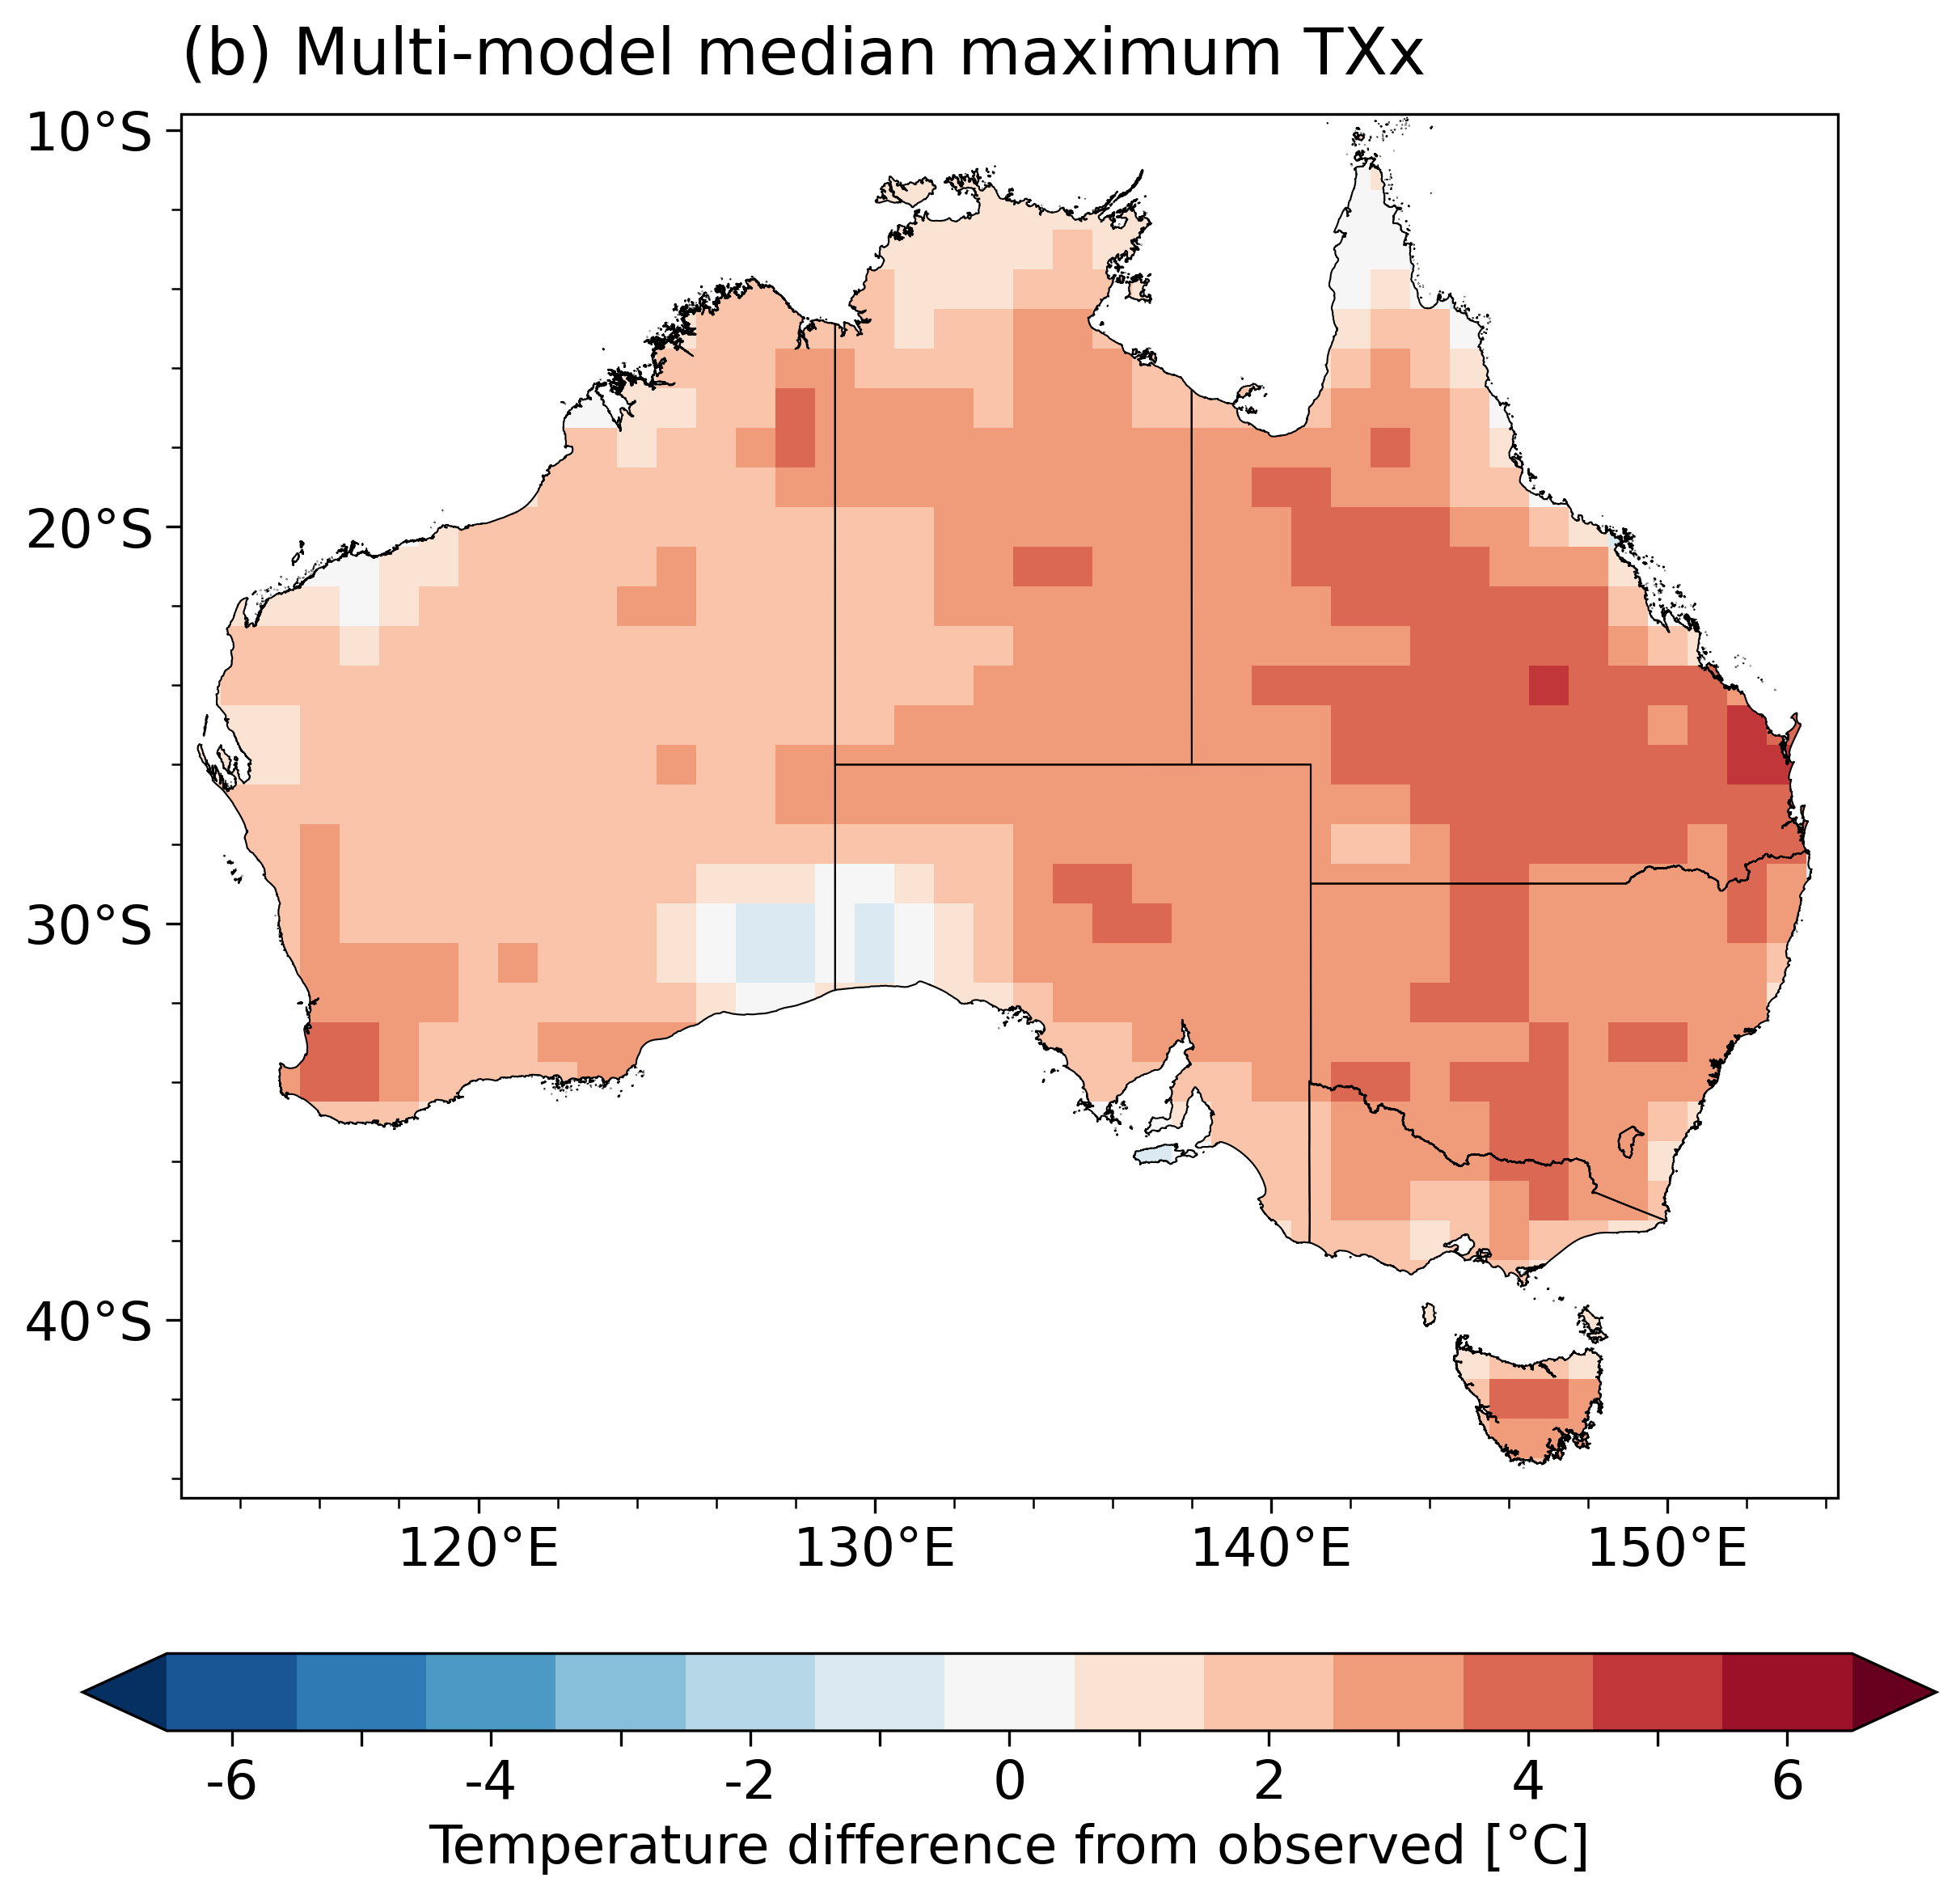

In [51]:
time_agg = "maximum"
fig, ax = plt.subplots(
    1, 1, figsize=(11, 7.7), subplot_kw=dict(projection=ccrs.PlateCarree())
)

# Models
da_list = []  # Store data arrays for the multi-model median
for i, m in enumerate(plot_dict["models"]):
    i += 2  # Leave ax[0-1] for obs & multi-model median

    da, kwargs = soft_record_metric(
        info[m].ds[var],
        info[m].obs_ds[var],
        time_agg,
        metric,
        plot_dict,
        time_dim=info[m].time_dim,
        dparams_ns=info[m].ds["dparams_ns"],
        covariate_base=covariate_base,
    )
    da_list.append(da)
kwargs["ticks"] = np.arange(-6.5, 7.5, 1)
# Multi-model median
i = 1
dm = multimodel_avg(info, plot_dict["models"], da_list)
fig, ax, cs = map_subplot(
    fig,
    ax,
    dm,
    cmap=kwargs["cmap"],
    ticks=kwargs["ticks"],
    extend=kwargs["cbar_extend"],
    vcentre=kwargs.get("vcentre", None),
    **map_plot_kwargs,
)
ax.set_title(
    f"{letters[1]} Multi-model median {time_agg} {plot_dict['metric']}",
    loc="left",
    y=1.015,
)

kwargs["cbar_label"] = kwargs["cbar_label"].replace("\n", " ")
ticks = kwargs["ticks"]
diff = np.ediff1d(ticks) / 2
ticklabels = np.around(np.array(ticks[:-1] + diff), 0).astype(int)
middle_ticks = np.around(np.array(ticks[:-1]) + diff / 2, 0).astype(int)

cbar = fig.colorbar(
    cs,
    ax=ax,
    ticks=middle_ticks,
    label="Temperature difference from observed [°C]",
    extend=kwargs["cbar_extend"],
    orientation="horizontal",
    fraction=0.1,
    shrink=0.7,
    aspect=24,
)
tick_interval = 2
cbar.ax.set_xticks(middle_ticks, ticklabels)
labels = cbar.ax.xaxis.get_ticklabels()
cbar.ax.minorticks_off()
for i, label in enumerate(labels):
    if i % tick_interval != 0:
        label.set_visible(False)

outfile = f"{plot_dict['fig_dir']}/{time_agg}_anom_mmm_{plot_dict['filestem']}.png"
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()

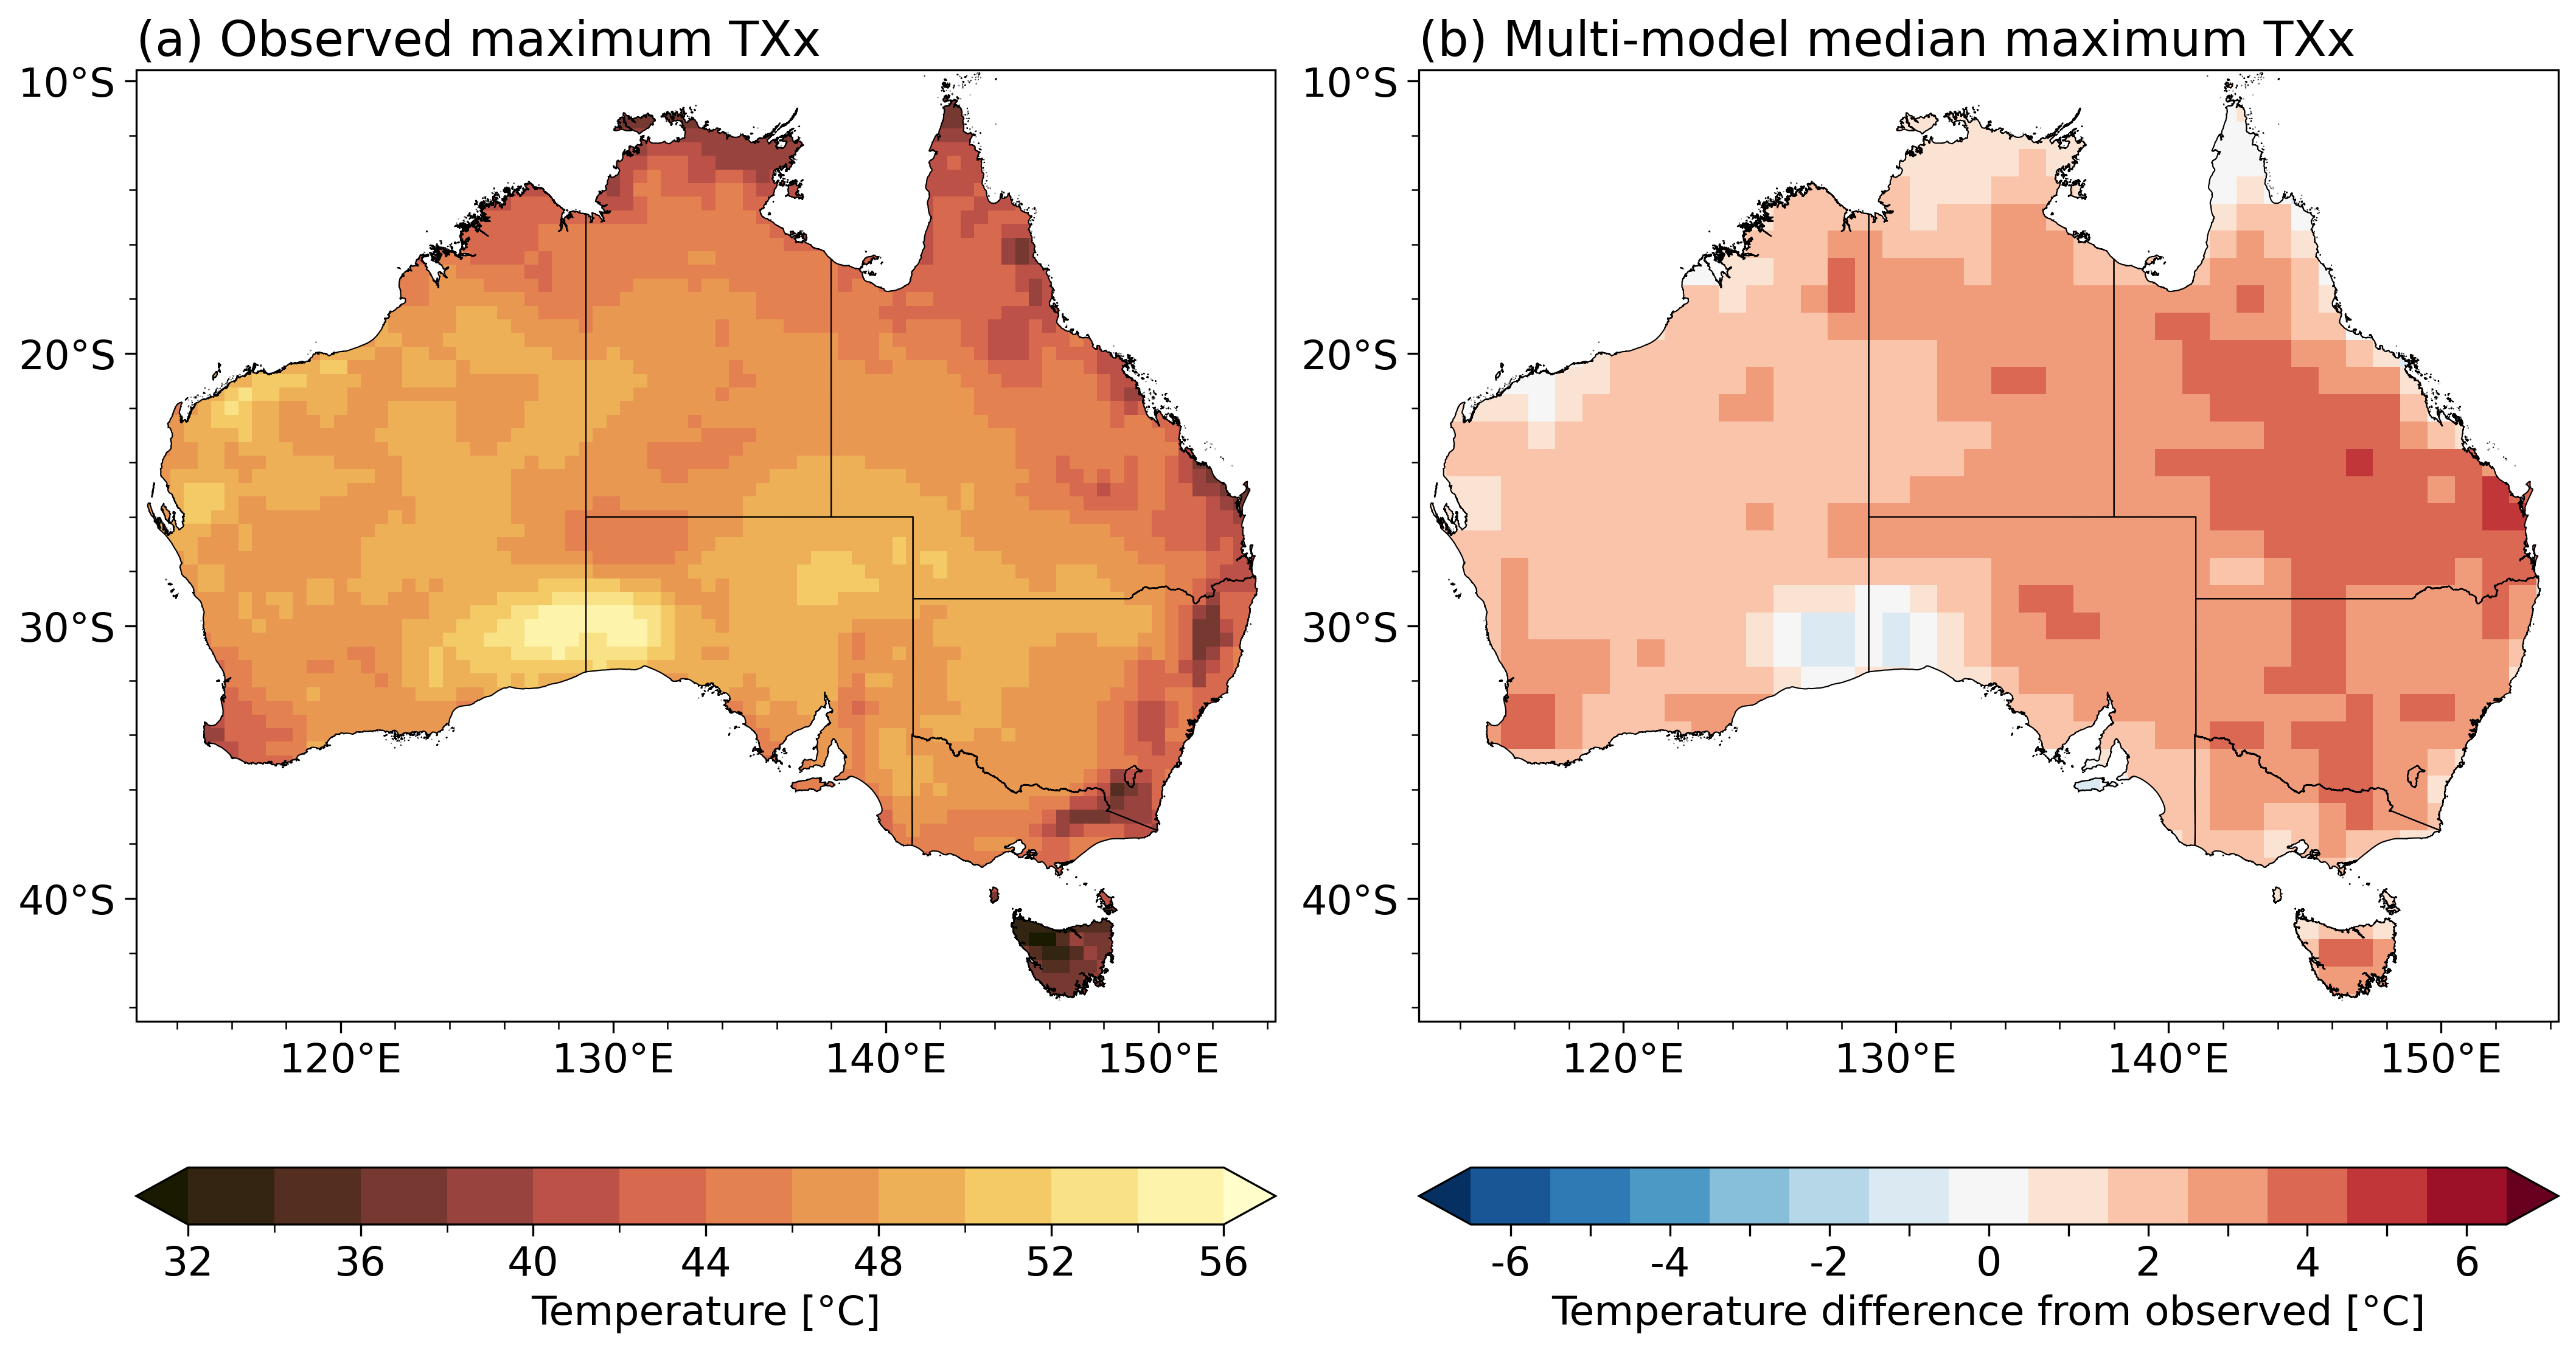

In [ ]:
time_agg = "maximum"
anom = "anom"
covariate_base = 2025
fig, ax = plt.subplots(1, 2, subplot_kw=dict(projection=ccrs.PlateCarree()))
ax = ax.flatten()

# Plot obs time agg
i = 0
da_obs = info[obs].ds[var].reduce(func_dict[time_agg], dim=info[obs].time_dim)
fig, ax[i], cs = map_subplot(
    fig,
    ax[i],
    da_obs,
    hatching=info[obs].pval_mask,
    cmap=plot_dict["cmap"],
    ticks=plot_dict["ticks"],
    extend=plot_dict["cbar_extend"],
    **map_plot_kwargs,
)
ax[i].set_title(f"{letters[i]} Observed {time_agg} {plot_dict['metric']}", loc="left")
cbar = fig.colorbar(cs, orientation="horizontal", label="Temperature [°C]")

# Models
da_list = []  # Store data arrays for the multi-model median
for i, m in enumerate(plot_dict["models"]):
    i += 2  # Leave ax[0-1] for obs & multi-model median

    da, kwargs = soft_record_metric(
        info[m].ds[var],
        info[m].obs_ds[var],
        time_agg,
        metric,
        plot_dict,
        time_dim=info[m].time_dim,
        dparams_ns=info[m].ds["dparams_ns"],
        covariate_base=covariate_base,
    )
    da_list.append(da)
kwargs["ticks"] = np.arange(-6.5, 7.5, 1)
# Multi-model median
i = 1
dm = multimodel_avg(info, plot_dict["models"], da_list)
fig, ax[i], cs = map_subplot(
    fig,
    ax[i],
    dm,
    cmap=kwargs["cmap"],
    ticks=kwargs["ticks"],
    extend=kwargs["cbar_extend"],
    vcentre=kwargs.get("vcentre", None),
    **map_plot_kwargs,
)
ax[i].set_title(
    f"{letters[i]} Multi-model median {time_agg} {plot_dict['metric']}", loc="left"
)

kwargs["cbar_label"] = kwargs["cbar_label"].replace("\n", " ")
ticks = kwargs["ticks"]
diff = np.ediff1d(ticks) / 2
ticklabels = np.around(np.array(ticks[:-1] + diff), 0).astype(int)
middle_ticks = np.around(np.array(ticks[:-1]) + diff / 2, 0).astype(int)

cbar = fig.colorbar(
    cs,
    ax=ax[i],
    ticks=middle_ticks,
    label="Temperature difference from observed [°C]",
    extend=kwargs["cbar_extend"],
    orientation="horizontal",
)
tick_interval = 2
cbar.ax.set_xticks(middle_ticks, ticklabels)
labels = cbar.ax.xaxis.get_ticklabels()
cbar.ax.minorticks_off()
for i, label in enumerate(labels):
    if i % tick_interval != 0:
        label.set_visible(False)

outfile = f"{plot_dict['fig_dir']}/{time_agg}_{anom}_{plot_dict['filestem']}.png"
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()

### Metric maximum (subsampled)

In [28]:
resamples = 1000
time_agg = "maximum"
n_obs_samples = info[obs].obs_ds[info[obs].var].time.size
da_obs = info[obs].ds[var].reduce(func_dict[time_agg], dim=info[obs].time_dim)
da_list = []  # Store data arrays for the multi-model median & anomaly plot
da_anom_list = []
for i, m in enumerate(plot_dict["models"]):
    i += 2  # Leave ax[0-1] for obs and the multi-model median
    da = resample_subsample(info[m], info[m].ds, time_agg, n_obs_samples, resamples)
    da_list.append(da)
    da_obs_regrid = general_utils.regrid(da_obs, da)
    da = da - da_obs_regrid
    da_anom_list.append(da)
dm = multimodel_avg(info, plot_dict["models"], da_anom_list)
# dm = multimodel_avg(info, plot_dict["models"], da_list)

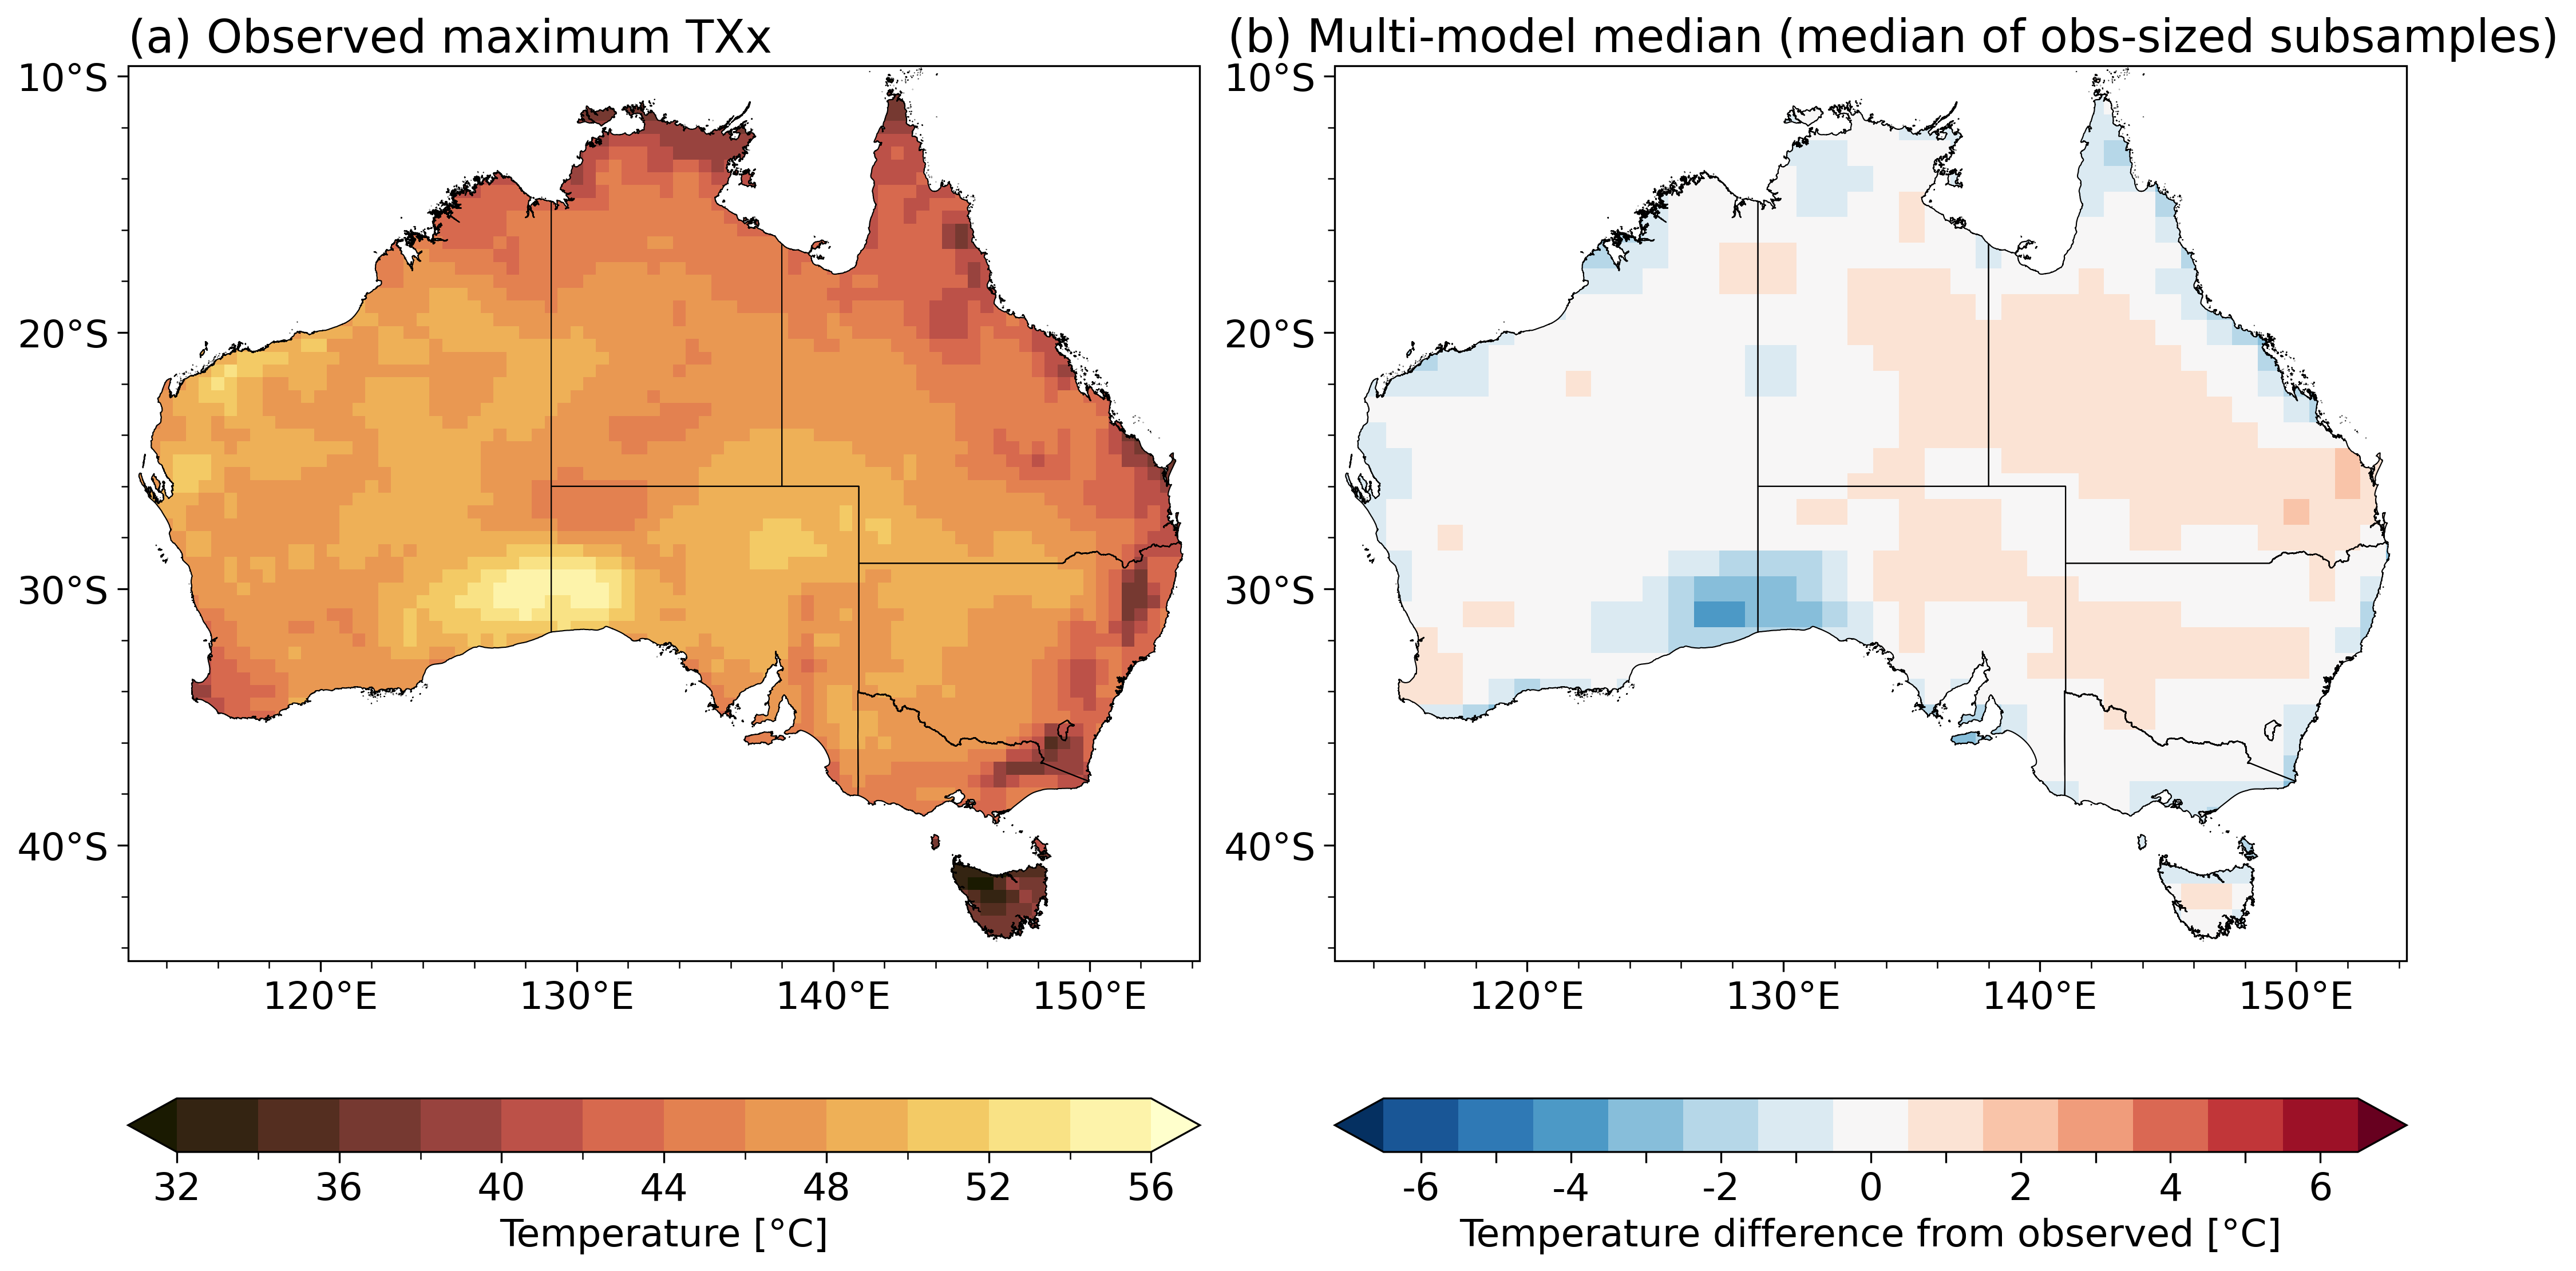

In [ ]:
cbar_kwargs = dict(
    cmap=plot_dict["cmap"],
    ticks=plot_dict["ticks"],
    extend=plot_dict["cbar_extend"],
    label="Temperature [°C]",
)

fig, ax = plt.subplots(1, 2, subplot_kw=dict(projection=ccrs.PlateCarree()))
ax = ax.flatten()

# Plot obs time agg (not anomaly)
i = 0
fig, ax[i], cs = map_subplot(
    fig,
    ax[i],
    da_obs,
    hatching=info[obs].pval_mask,
    **cbar_kwargs,
    **map_plot_kwargs,
)
ax[i].set_title(f"{letters[i]} Observed {time_agg} {plot_dict['metric']}", loc="left")
# cbar = fig.colorbar(cs, orientation="horizontal", label="Temperature [°C]")
cbar = fig.colorbar(cs, orientation="horizontal", label="Temperature [°C]")
# Multi-model median
ticks = np.arange(-6.5, 7.5, 1)
cbar_kwargs = dict(
    cmap=plot_dict["cmap_anom"],
    extend="both",
    ticks=ticks,
    label="Temperature difference from observed [°C]",
)

diff = np.ediff1d(ticks) / 2
ticklabels = np.around(np.array(ticks[:-1] + diff), 0).astype(int)
middle_ticks = np.around(np.array(ticks[:-1]) + diff / 2, 0).astype(int)
i = 1
fig, ax[i], cs = map_subplot(
    fig,
    ax[i],
    dm,
    **cbar_kwargs,
    **map_plot_kwargs,
)
ax[i].set_title(
    f"{letters[i]} Multi-model median (median of obs-sized subsamples)",
    loc="left",
    x=-0.1,
    y=1.015,
)
cbar = fig.colorbar(
    cs,
    ax=ax[i],
    ticks=middle_ticks,
    label="Temperature difference from observed [°C]",
    extend="both",
    orientation="horizontal",
)
tick_interval = 2
cbar.ax.set_xticks(middle_ticks, ticklabels)
axis = "x"
labels = eval(f"cbar.ax.{axis}axis.get_ticklabels()")
cbar.ax.minorticks_off()
for j, label in enumerate(labels):
    if j % tick_interval != 0:
        label.set_visible(False)


# cbar = add_shared_colorbar(
#     fig,
#     ax[i],
#     cs,
#     **cbar_kwargs,
# )


outfile = (
    f"{plot_dict['fig_dir']}/{time_agg}_subsampled_anom_{plot_dict['filestem']}.png"
)
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()

### New record probability

In [20]:
time_agg = "maximum"
start_year = 2025
n_years = 10

# Get metric in each model
da_list = []
for i, m in enumerate(plot_dict["models"]):
    record = info[m].obs_ds[info[m].var].reduce(func_dict[time_agg], dim="time")
    if info[m].is_model():
        record = general_utils.regrid(record, info[m].ds)
    cumulative_probability = nonstationary_new_record_probability(
        record, info[m].ds.dparams_ns, start_year, n_years, info[m].time_dim
    )
    da = cumulative_probability * 100
    da_list.append(da)

dm = multimodel_avg(info, plot_dict["models"], da_list)

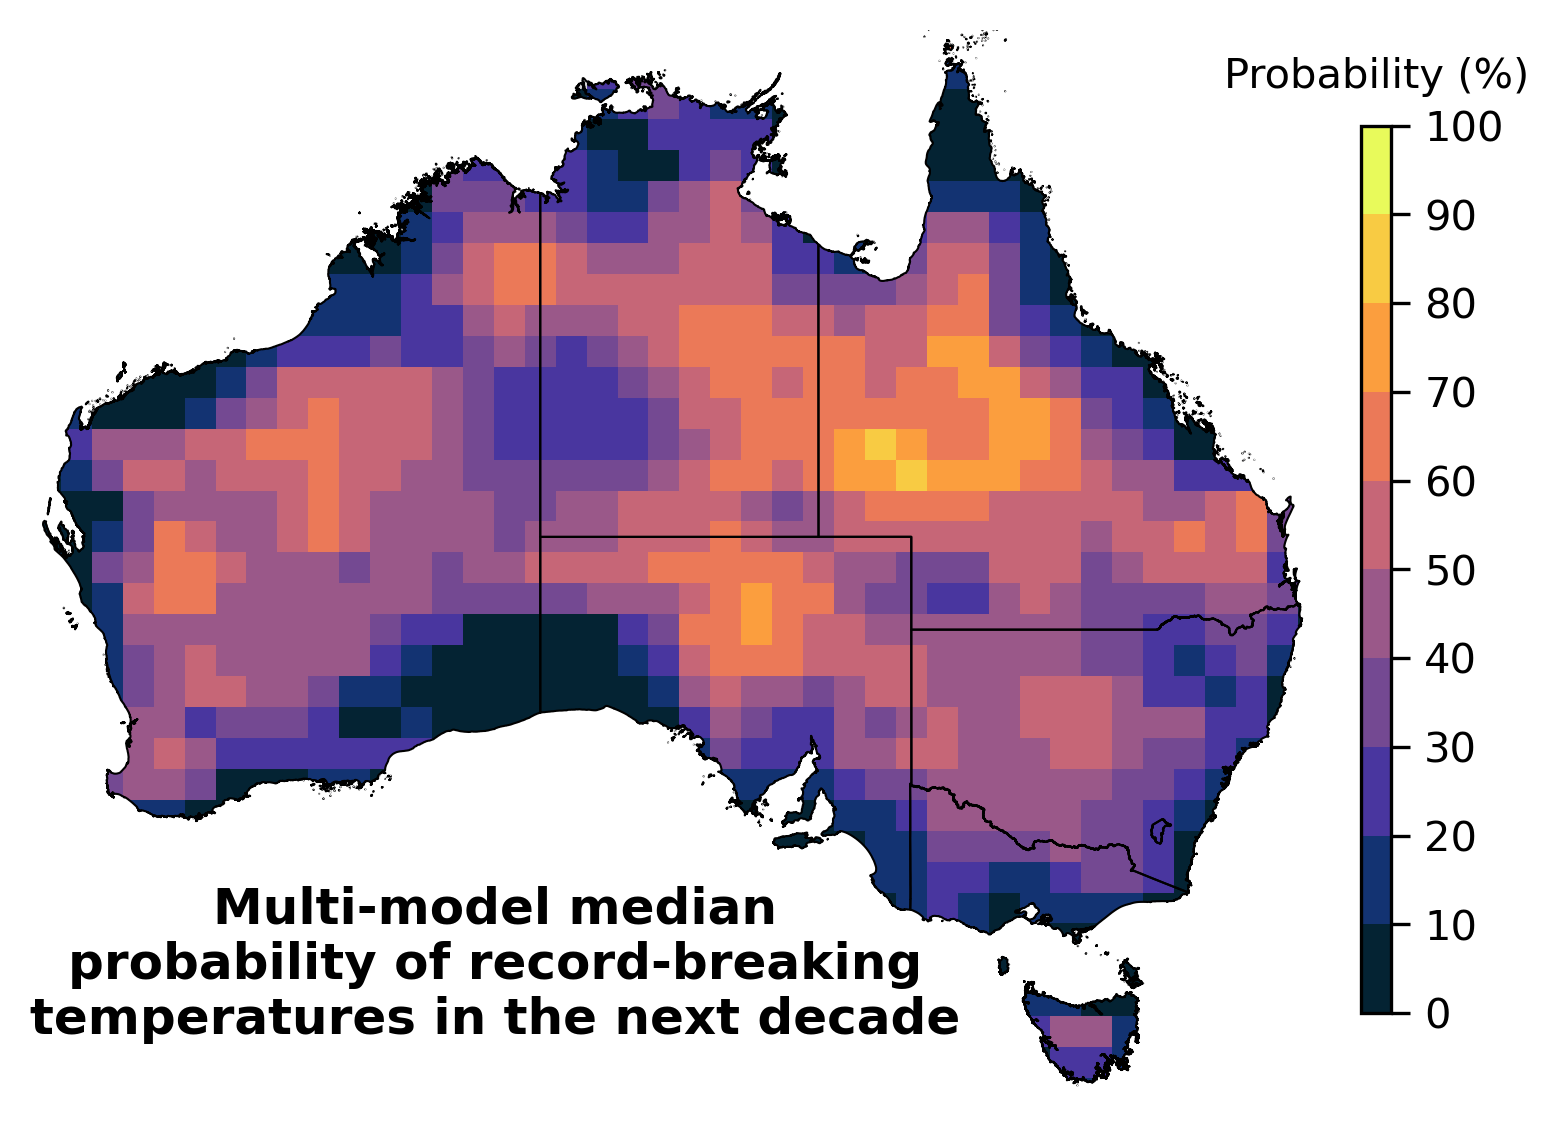

In [21]:
plt.rcParams.update({"font.size": 10})
cbar_kwargs = dict(
    cmap=cmocean.cm.thermal, ticks=np.arange(0, 101, 10), extend="neither"
)

fig, ax = plt.subplots(
    1, 1, figsize=(5, 6), dpi=300, subplot_kw=dict(projection=ccrs.PlateCarree())
)
fig, ax, cs = map_subplot(fig, ax, dm, **cbar_kwargs, **map_plot_kwargs)

cbar = add_shared_colorbar(
    fig,
    ax,
    cs,
    orientation="vertical",
    aspect=30,
    pad=0.03,
    shrink=0.5,
    fraction=0.9,
    **cbar_kwargs,
)
cbar.ax.set_title("Probability (%)", fontsize=10, pad=9)

# Hide the x and y axes and ticks
ax.set_axis_off()
ax.text(
    x=0.36,
    y=0.06,
    s=f"Multi-model median\nprobability of record-breaking\n{plot_dict['var_name'].lower()}s in the next decade",
    fontsize=12,
    weight="bold",
    ha="center",
    va="bottom",
    transform=ax.transAxes,
    zorder=10,
    wrap=1,
)

plt.savefig(
    f"{plot_dict['fig_dir']}/abstract_{plot_dict['filestem']}.png",
    bbox_inches="tight",
)
plt.show()
plt.close()
plt.rcParams.update({"font.size": fontsize})

### Annual exceedance probability (AEP) trend

In [52]:
aep = 1
ari = eva.aep_to_ari(aep)
da_list = []
for i, m in enumerate(info.keys()):
    _covariates = xr.DataArray(covariates, dims=info[m].time_dim)
    da = eva.get_return_level(ari, info[m].ds.dparams_ns, _covariates)
    da = da.isel({info[m].time_dim: -1}, drop=True) - da.isel(
        {info[m].time_dim: 0}, drop=True
    )
    # Convert to per decade (trend/#intervals x 10 intervals)
    da = (da / (covariates[-1] - covariates[0])) * 10
    da_list.append(da)
dm = multimodel_avg(info, plot_dict["models"], da_list[1:])

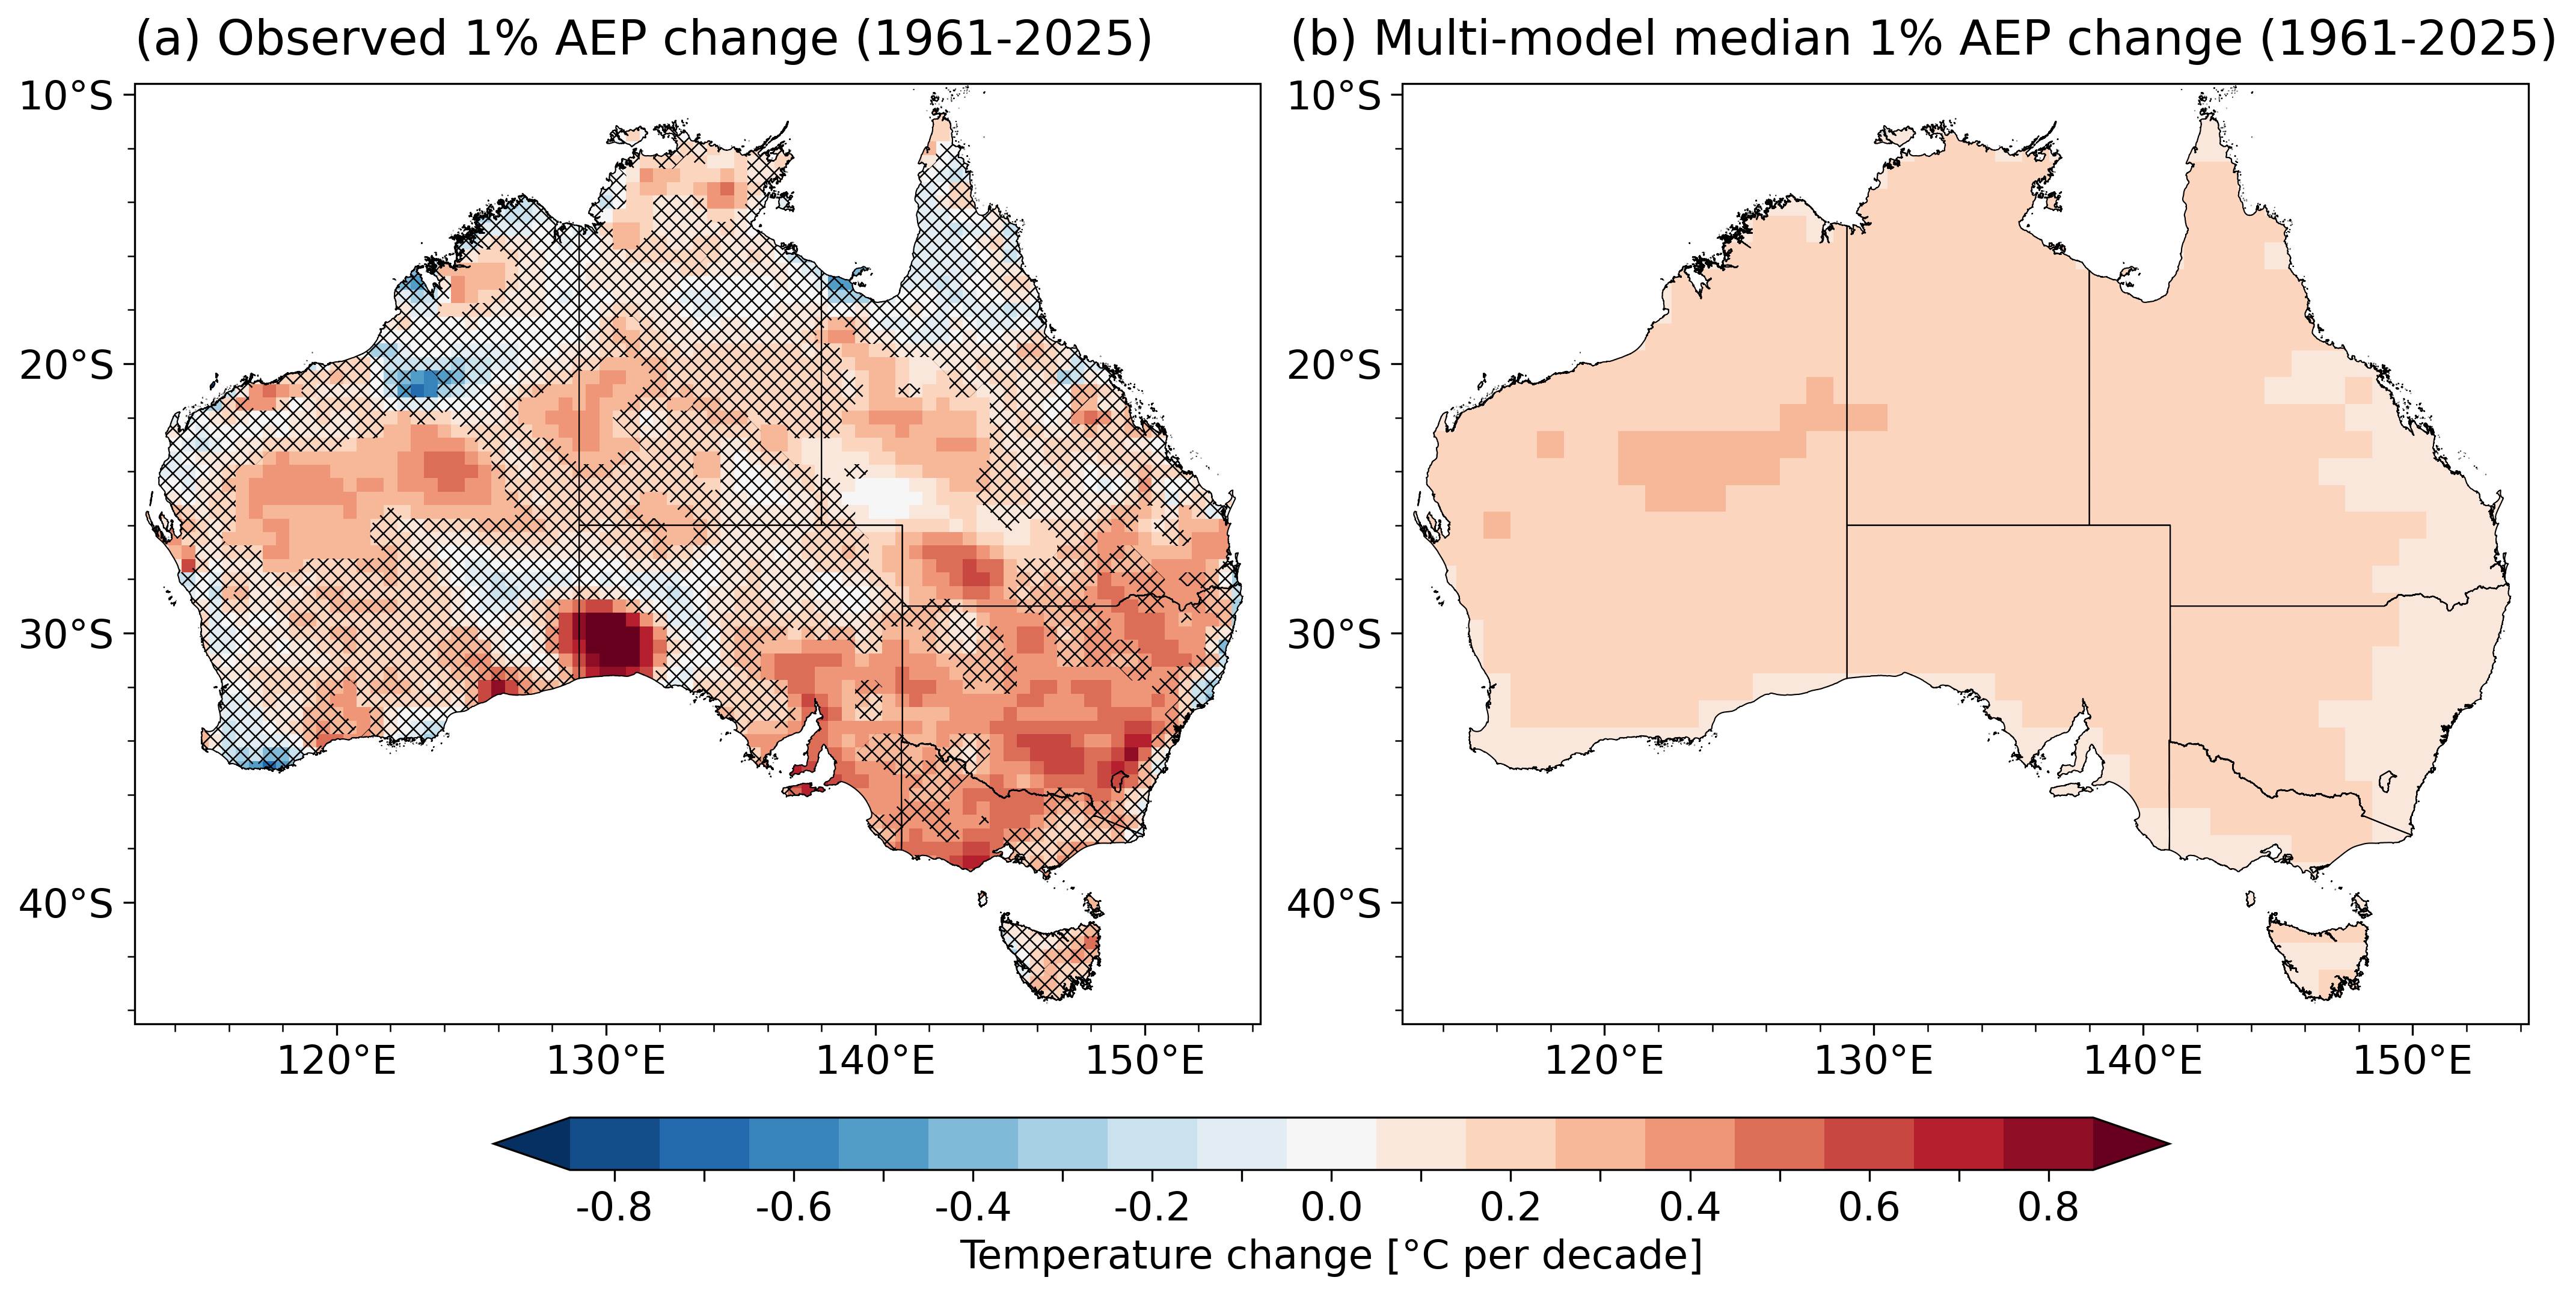

In [54]:
cbar_kwargs = dict(
    cmap=plot_dict["cmap_anom"],
    ticks=plot_dict["ticks_trend"],
    extend="both",
    ticklabels=np.around(
        plot_dict["ticks_trend"][:-1] + np.diff(plot_dict["ticks_trend"]) / 2,
        1,
    ),
)

fig, ax = plt.subplots(1, 2, subplot_kw=dict(projection=ccrs.PlateCarree()))
ax = ax.flatten()

# Plot obs trend
i = 0
fig, ax[i], cs = map_subplot(
    fig,
    ax[i],
    da_list[0],
    hatching=info[obs].gev_mask,
    **cbar_kwargs,
    **map_plot_kwargs,
)
ax[i].set_title(f"{letters[i]} Observed 1% AEP change (1961-2025)", loc="left", y=1.015)
# cbar = fig.colorbar(cs, orientation="horizontal", label="Temperature [°C]")

# Multi-model median
i = 1

fig, ax[i], cs = map_subplot(fig, ax[i], dm, **cbar_kwargs, **map_plot_kwargs)
ax[i].set_title(
    f"{letters[i]} Multi-model median 1% AEP change (1961-2025)",
    loc="left",
    x=-0.1,
    y=1.015,
)
cbar = add_shared_colorbar(
    fig,
    ax,
    cs,
    tick_interval=2,
    label="Temperature change [°C per decade]",
    **cbar_kwargs,
)

outfile = f"{plot_dict['fig_dir']}/aep_{aep:g}pct_trend_{plot_dict['filestem']}.png"
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()

In [ ]:
plot_dict["ticks_trend"]
np.around(
    plot_dict["ticks_trend"][:-1] + np.diff(plot_dict["ticks_trend"]) / 2,
    1,
)
np.arange(-0.6, 0.7, 0.1)
plot_dict["ticks_trend"] = np.around(np.arange(-0.4, 0.45, 0.1), 2)
plot_dict["ticks_trend"] + 
np.diff(plot_dict["ticks_trend"])[1:] / 2

ValueError: operands could not be broadcast together with shapes (9,) (7,) 

[-0.45 -0.35 -0.25 -0.15 -0.05  0.05  0.15  0.25  0.35  0.45]


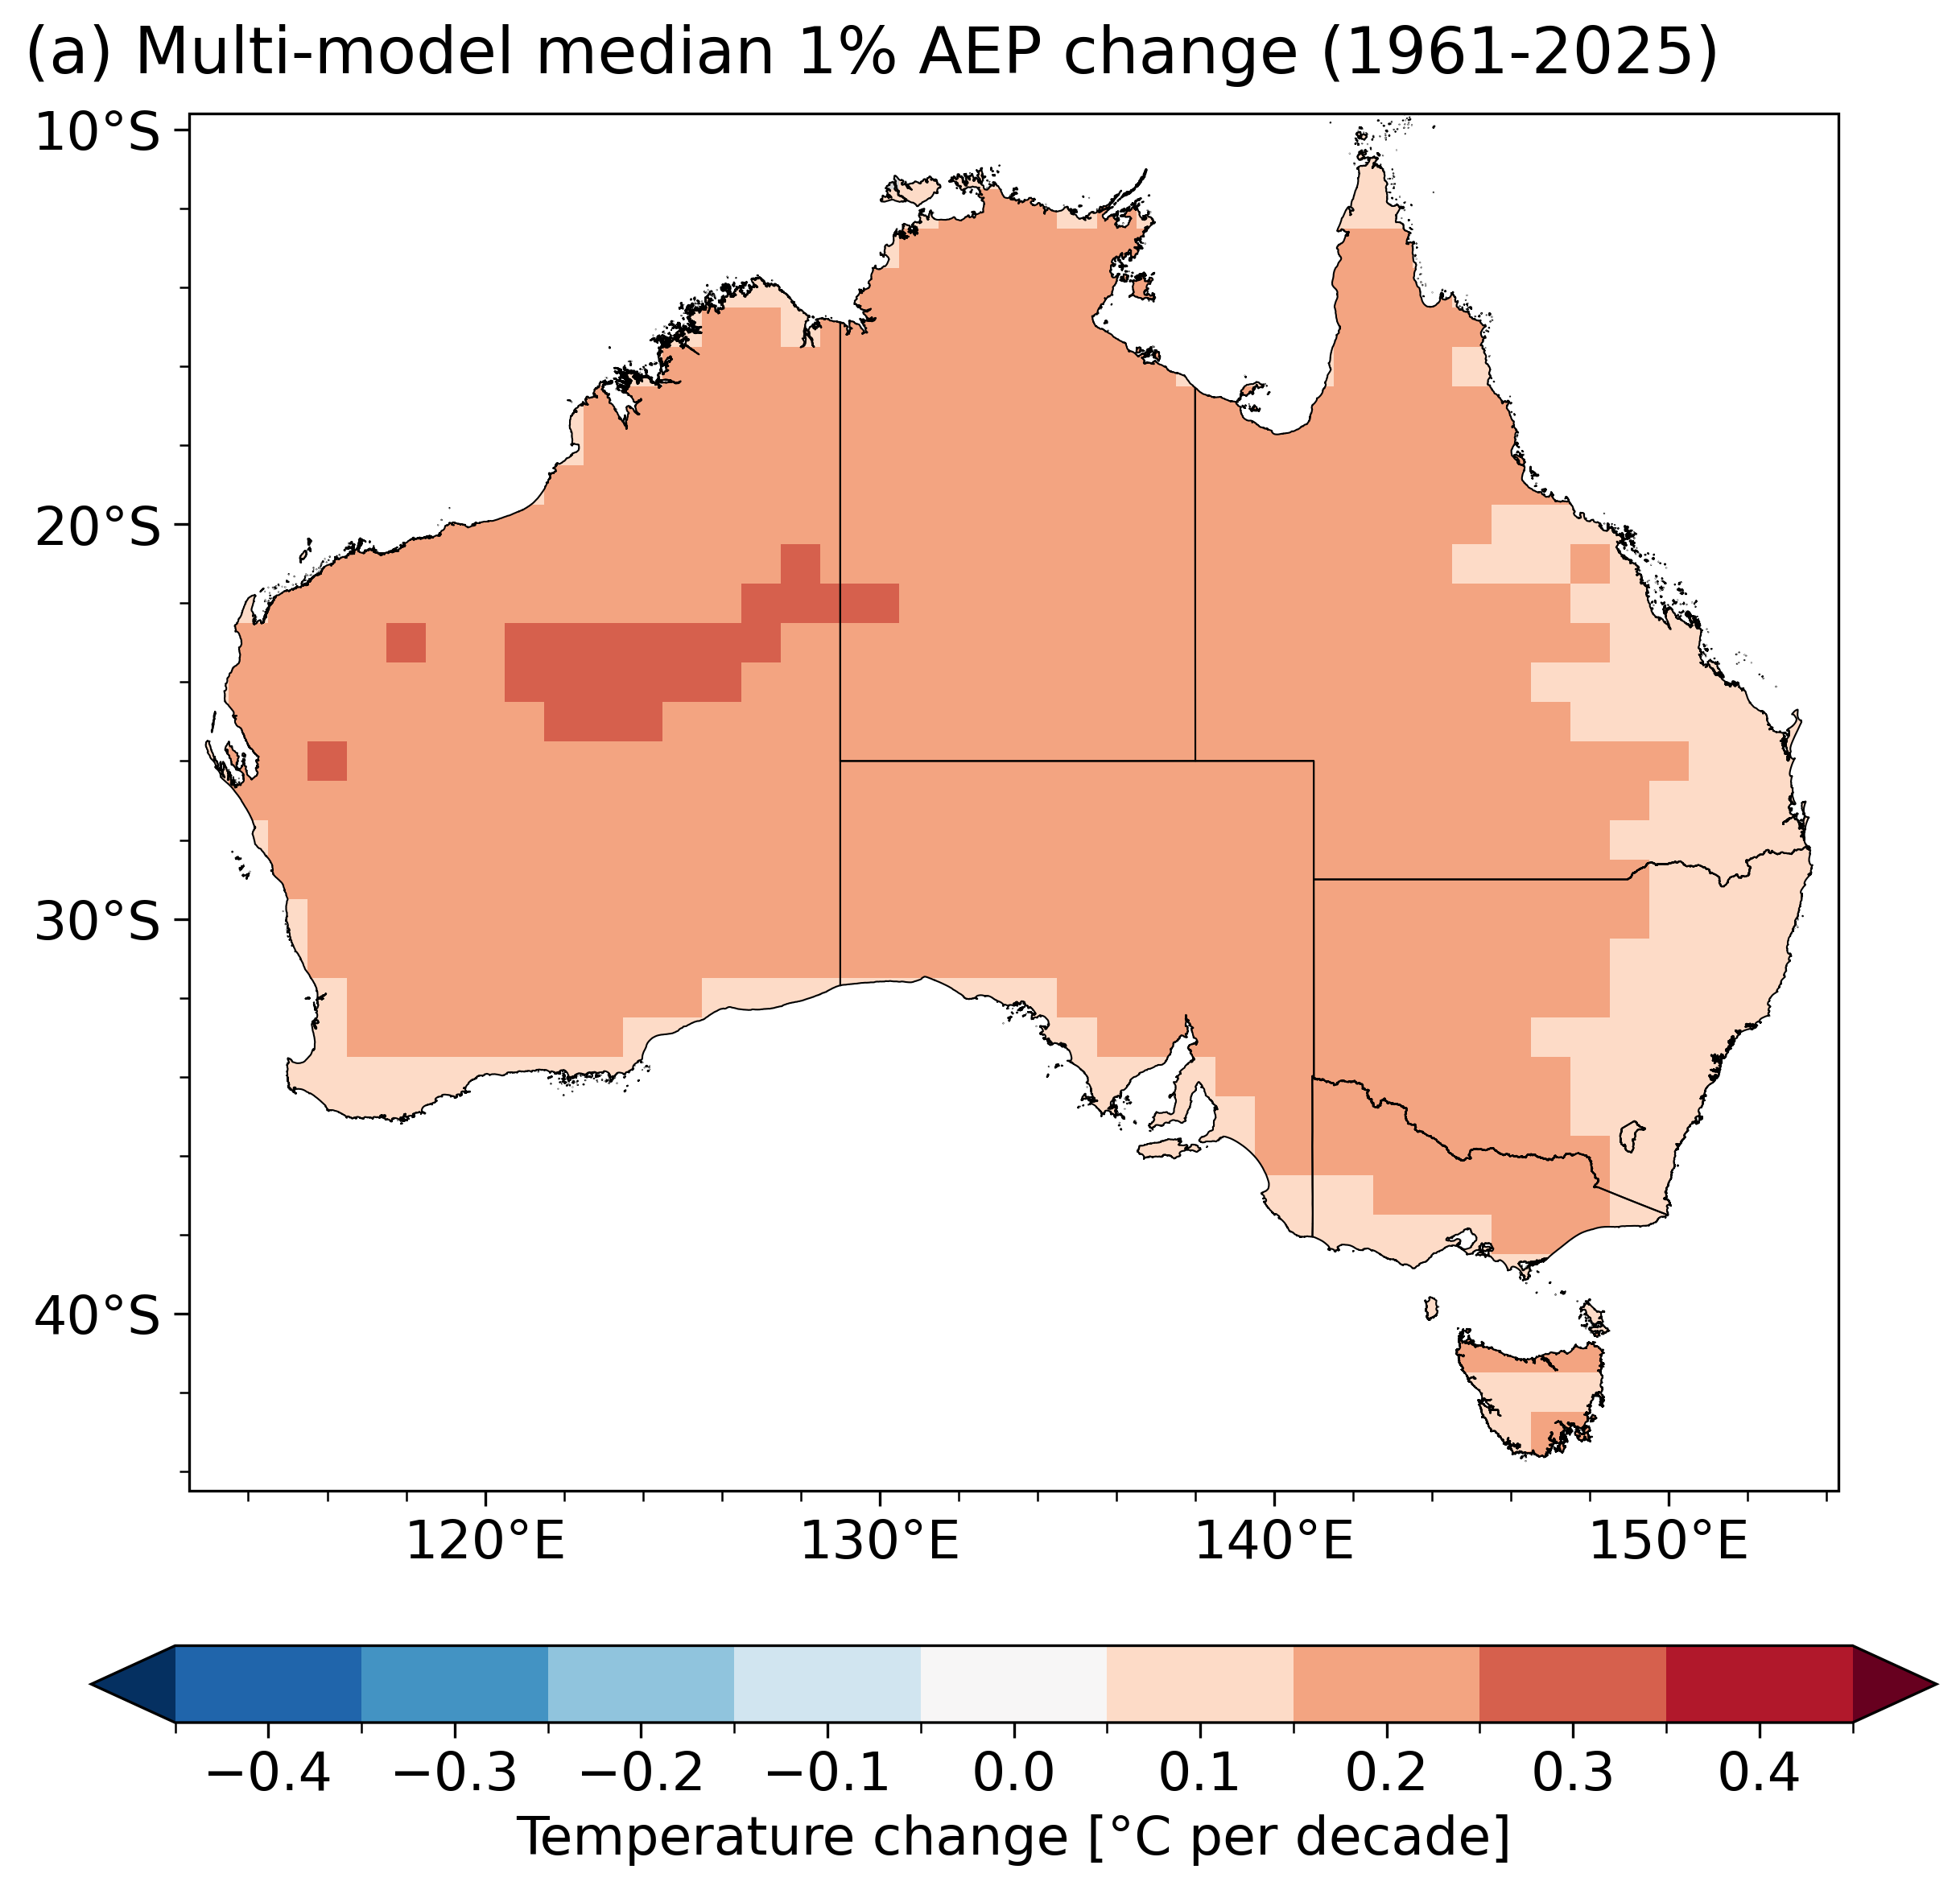

In [105]:
plot_dict["ticks_trend"] = np.around(np.arange(-0.45, 0.5, 0.1), 2)
cbar_kwargs = dict(
    cmap=plot_dict["cmap_anom"],
    ticks=plot_dict["ticks_trend"],
    extend="both",
)
print(cbar_kwargs["ticks"])
# print(cbar_kwargs["ticklabels"])
fig, ax = plt.subplots(
    1, 1, figsize=(11, 7.7), subplot_kw=dict(projection=ccrs.PlateCarree())
)

fig, ax, cs = map_subplot(fig, ax, dm, **cbar_kwargs, **map_plot_kwargs)
ax.set_title(
    f"{letters[0]} Multi-model median 1% AEP change (1961-2025)",
    loc="left",
    x=-0.1,
    y=1.015,
)


ticks = cbar_kwargs["ticks"]
diff = np.ediff1d(ticks) / 2
ticklabels = np.around(np.array(ticks[:-1] + diff), 1)
middle_ticks = np.around(np.array(ticks[:-1]) + diff / 2, 1)
cbar = fig.colorbar(
    cs,
    ax=ax,
    ticks=middle_ticks,
    label="Temperature change [°C per decade]",
    extend=cbar_kwargs["extend"],
    orientation="horizontal",
    fraction=0.1,
    shrink=0.7,
    aspect=24,
)
# tick_interval = 2
# # cbar.ax.set_xticks(ticks, ticklabels)
# cbar.ax.minorticks_off()
# cbar.ax.set_xticks(middle_ticks, ticklabels)
# labels = cbar.ax.xaxis.get_ticklabels()
# for i, label in enumerate(labels):
#     if i % tick_interval != 0:
#         label.set_visible(False)

outfile = f"{plot_dict['fig_dir']}/aep_{aep:g}pct_trend_mmm_{plot_dict['filestem']}.png"
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()

## Event year

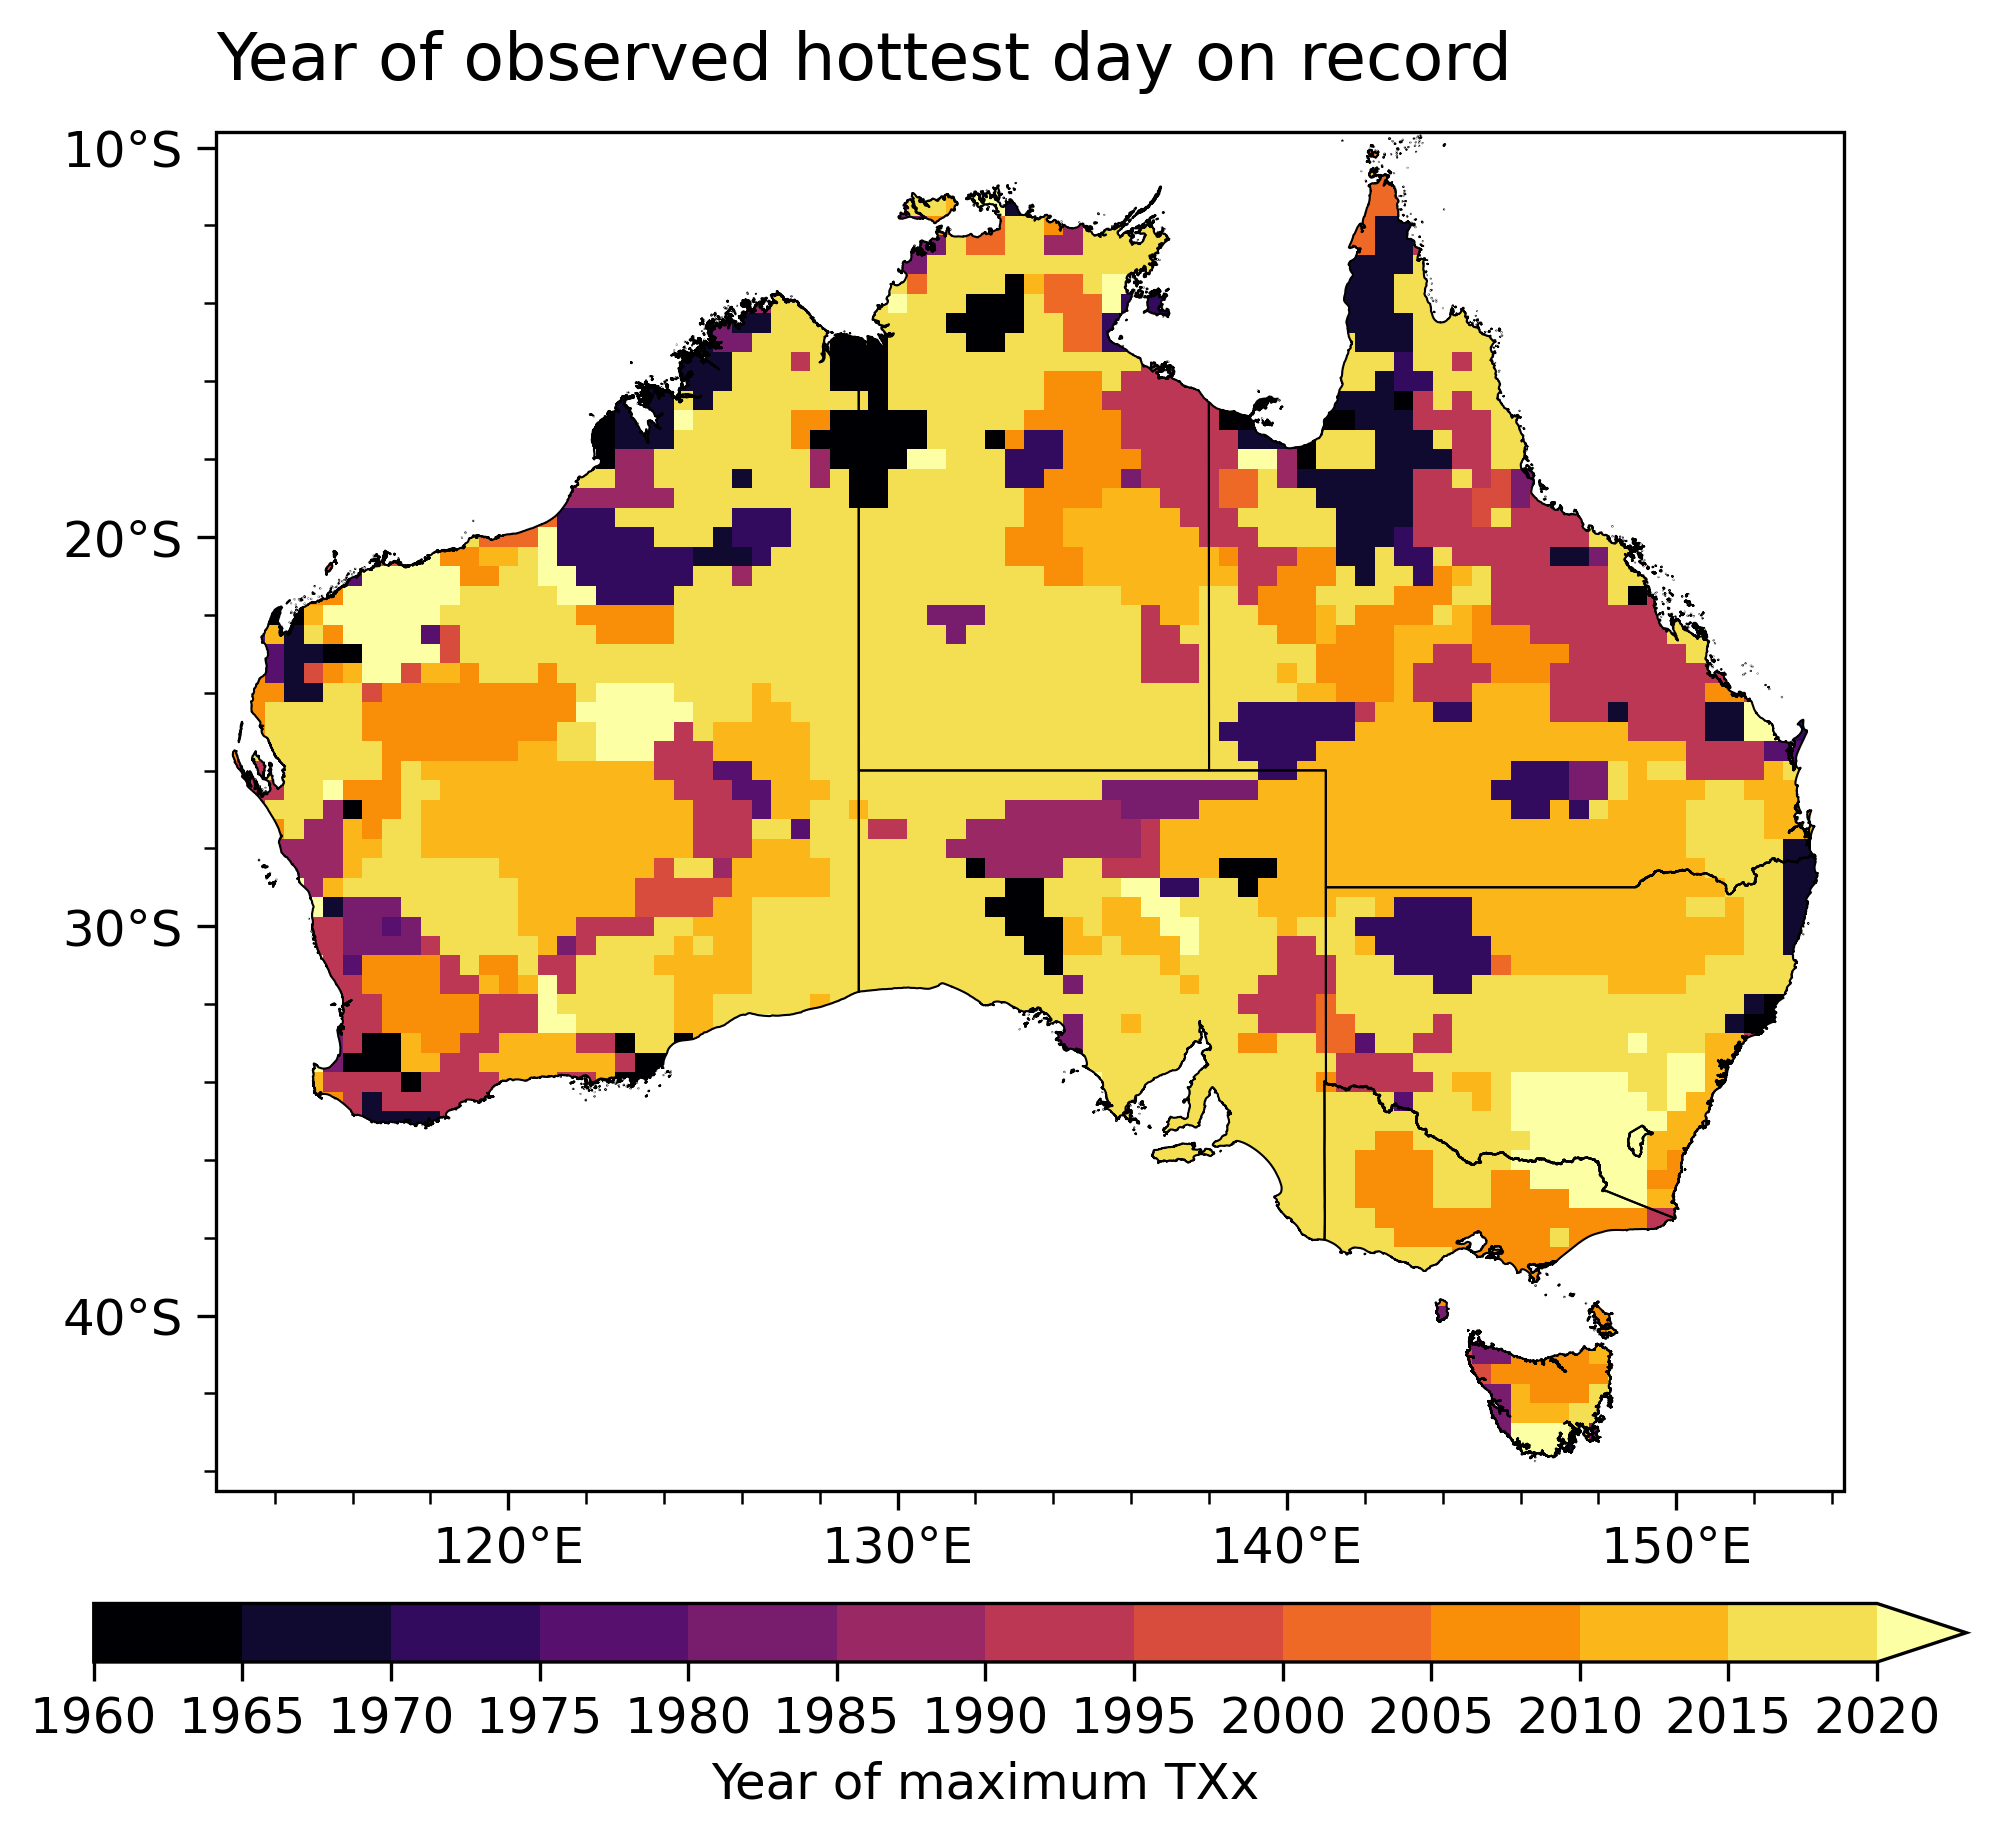

In [ ]:
ticks = np.arange(1960, 2025, 5)
min_count = 4
plt.rcParams.update({"font.size": 12})
cbar_kwargs = dict(
    cmap=cmap_dict["inferno"],
    ticks=ticks,
    extend="max",
)
fig, ax = plt.subplots(
    1, 1, figsize=(9, 6), subplot_kw=dict(projection=ccrs.PlateCarree())
)
m = obs

# Change the time dimension to event year
dt = info[m].ds[var].copy().compute()
dt.coords[info[m].time_dim] = dt.event_time.dt.year

# Get the year of the maximum or minimum event
if time_agg == "maximum":
    da = dt.idxmax(info[m].time_dim)
elif time_agg == "minimum":
    da = dt.idxmin(info[m].time_dim)
fig, ax, cs = map_subplot(
    fig,
    ax,
    da,
    **cbar_kwargs,
    **map_plot_kwargs,
)
ax.set_title(
    f"Year of observed hottest day on record",
    loc="left",
    y=1.015,
    fontsize=fontsize,
)
add_shared_colorbar(
    fig,
    ax,
    cs,
    label=f"Year of {time_agg} {plot_dict['metric']}",
    **cbar_kwargs,
)

outfile = f"{plot_dict['fig_dir']}/year_{time_agg}_{plot_dict['filestem']}.png"
plt.savefig(outfile, bbox_inches="tight")
plt.show()
plt.close()


plt.rcParams.update({"font.size": fontsize})